# VisuoGrasp V3 ACTIVE

The single working notebook for the V3 experiments. Built by `build_v3_active_notebook.py`
from the V2 notebook, which stays untouched as the record of the V2 runs.

- Reused without change: robot, objects, D0, confirmation rule, base environment, CV V2 detectors, callback and resume helpers.
- Removed: dataset collection, detector training, V2 DRL training and sections 10-13.
- All new outputs go to `visuograsp_full_outputs/cv_v2/drl_runs_v3_final/`.

Edit only `V3_STAGE` in the last cell. Stages: `gate`, `train`, `eval`, `report`.

**V3.3:** n-step SAC critic fix inserted before run control; see that cell.


In [1]:
import os, sys
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ.setdefault('MUJOCO_GL','egl')
import math, time, json, random, gc, warnings, platform
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from collections import deque, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cv2, imageio.v2 as imageio
import mujoco, gymnasium as gym
from gymnasium import spaces
from scipy.spatial.transform import Rotation
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, confusion_matrix
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from stable_baselines3 import SAC, TD3, PPO
from stable_baselines3.common.callbacks import BaseCallback, CheckpointCallback
from stable_baselines3.common.monitor import Monitor
from IPython.display import display, Image
from tqdm.auto import tqdm

ROOT = Path('visuograsp_full_outputs').resolve()
for sub in ['models','detectors','data','videos','figures','logs','results','scenes']:
    (ROOT/sub).mkdir(parents=True, exist_ok=True)
SEEDS = (11,22,33,44,55)
GLOBAL_SEED = 11
random.seed(GLOBAL_SEED); np.random.seed(GLOBAL_SEED); torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(GLOBAL_SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Python',platform.python_version(),'MuJoCo',mujoco.__version__, 'PyTorch',torch.__version__, 'training device',DEVICE)
print('Project outputs:', ROOT)

@dataclass
class FullConfig:
    # Full-size experimental budgets and independent seeds.
    policy_hz: int = 20
    physics_dt: float = 0.0025
    image_size: int = 128
    patch_size: int = 32
    episode_steps: int = 200
    detector_dataset_episodes: int = 620
    detector_max_samples: int = 40_000
    detector_epochs: int = 50
    detector_checkpoint_batches: int = 50
    detector_batch: int = 128
    main_steps: int = 2_000_000             # each training seed and condition
    full_seeds: tuple = SEEDS
    eval_episodes_per_object: int = 50
    hold_frames: int = 60                  # 3 seconds at 20 Hz
    contact_threshold_n: float = 0.2
    confirm_k: int = 3
    release_m: int = 2
    threshold_high: float = 0.55
    threshold_low: float = 0.35
    train_level: str = 'A'
    secondary_level: str = 'B'
    render_every_step: bool = True

CFG = FullConfig()
print(json.dumps(asdict(CFG),indent=2,default=list))
(ROOT/'config.json').write_text(json.dumps(asdict(CFG),indent=2,default=list),encoding='utf-8')

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Python 3.13.2 MuJoCo 3.17.0 PyTorch 2.7.1+cu118 training device cuda
Project outputs: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs
{
  "policy_hz": 20,
  "physics_dt": 0.0025,
  "image_size": 128,
  "patch_size": 32,
  "episode_steps": 200,
  "detector_dataset_episodes": 620,
  "detector_max_samples": 40000,
  "detector_epochs": 50,
  "detector_checkpoint_batches": 50,
  "detector_batch": 128,
  "main_steps": 2000000,
  "full_seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "eval_episodes_per_object": 50,
  "hold_frames": 60,
  "contact_threshold_n": 0.2,
  "confirm_k": 3,
  "release_m": 2,
  "threshold_high": 0.55,
  "threshold_low": 0.35,
  "train_level": "A",
  "secondary_level": "B",
  "render_every_step": true
}


602

In [2]:
TRAIN_SHAPES=('sphere','box','cylinder','ellipsoid','capsule','ring')
TEST1_SHAPES=TRAIN_SHAPES
TEST2_SHAPES=('cone','hex_prism','l_shape','mug','bottle')
ALL_SHAPES=TRAIN_SHAPES+TEST2_SHAPES
PAD_RADIUS=0.009
FINGER_LINKS=(0.030,0.027,0.022,0.018)
# Geometries are in meters; a mass of 0.05–0.3 kg is assigned per episode.

def camera_quat(eye,target):
    eye=np.asarray(eye,dtype=float); f=np.asarray(target,dtype=float)-eye
    f=f/np.linalg.norm(f)
    right=np.cross(f,[0.,0.,1.]); right=right/np.linalg.norm(right)
    up=np.cross(right,f)
    xyzw=Rotation.from_matrix(np.column_stack((right,up,-f))).as_quat()
    return ' '.join(f'{v:.9g}' for v in [xyzw[3],*xyzw[:3]])

def object_xml(shape,scale=1.0,mass=.13):
    """Return collision/visual geom XML + approximate resting center height."""
    s=float(scale)
    def g(name,typ,size,pos='0 0 0',extra=''):
        placement='' if 'fromto=' in extra else f'pos="{pos}"'
        return f'<geom name="{name}" type="{typ}" size="{size}" {placement} {extra} rgba=".90 .13 .11 1"/>'
    geoms=[]; radius=.034*s
    if shape=='sphere':
        z=.034*s; geoms=[g('object_geom','sphere',f'{z:.6f}')]
    elif shape=='box':
        z=.032*s; geoms=[g('object_geom','box',f'{.029*s:.6f} {.029*s:.6f} {z:.6f}')]
    elif shape=='cylinder':
        z=.036*s; geoms=[g('object_geom','cylinder',f'{.029*s:.6f} {z:.6f}')]
    elif shape=='ellipsoid':
        z=.038*s; geoms=[g('object_geom','ellipsoid',f'{.029*s:.6f} {.026*s:.6f} {z:.6f}')]
    elif shape=='capsule':
        z=.050*s; geoms=[g('object_geom','capsule',f'{.024*s:.6f} {.026*s:.6f}')]
    elif shape=='ring':
        z=.013*s
        # Ring lying flat; twelve overlapping capsule segments, one rigid body.
        for j in range(12):
            a=2*math.pi*j/12; bb=2*math.pi*(j+1)/12
            p1=np.array([.033*s*math.cos(a),.033*s*math.sin(a),0]); p2=np.array([.033*s*math.cos(bb),.033*s*math.sin(bb),0])
            fto=' '.join(f'{v:.6f}' for v in [*p1,*p2])
            geoms.append(g('object_geom' if j==0 else f'object_piece_{j}','capsule',f'{.009*s:.6f}',extra=f'fromto="{fto}"'))
    elif shape=='cone':
        z=.038*s
        for j in range(12):
            a=2*math.pi*j/12; p=[.03*s*math.cos(a),.03*s*math.sin(a),-.030*s]
            t=' '.join(f'{v:.6f}' for v in [*p,0,0,.034*s])
            geoms.append(g('object_geom' if j==0 else f'object_piece_{j}','capsule',f'{.006*s:.6f}',extra=f'fromto="{t}"'))
    elif shape=='hex_prism':
        z=.038*s
        for j in range(6):
            a=2*math.pi*j/6
            geoms.append(g('object_geom' if j==0 else f'object_piece_{j}','box',f'{.018*s:.6f} {.015*s:.6f} {.037*s:.6f}',
                           pos=f'{.012*s*math.cos(a):.6f} {.012*s*math.sin(a):.6f} 0',extra=f'euler="0 0 {math.degrees(a):.5f}"'))
    elif shape=='l_shape':
        z=.034*s
        geoms=[g('object_geom','box',f'{.012*s:.6f} {.032*s:.6f} {z:.6f}',pos=f'{-.018*s:.6f} 0 0'),
               g('object_piece_1','box',f'{.034*s:.6f} {.012*s:.6f} {z:.6f}',pos=f'0 {-.02*s:.6f} 0')]
    elif shape=='mug':
        z=.040*s
        geoms=[g('object_geom','cylinder',f'{.028*s:.6f} {z:.6f}')]
        for j,(p1,p2) in enumerate([((.026,0,-.018),(.056,0,-.018)),((.056,0,-.018),(.056,0,.020)),((.056,0,.020),(.026,0,.020))]):
            t=' '.join(f'{v*s:.6f}' for v in (*p1,*p2))
            geoms.append(g(f'object_piece_{j+1}','capsule',f'{.006*s:.6f}',extra=f'fromto="{t}"'))
    elif shape=='bottle':
        z=.059*s
        geoms=[g('object_geom','cylinder',f'{.029*s:.6f} {.036*s:.6f}',pos=f'0 0 {-.019*s:.6f}'),
               g('object_piece_1','cylinder',f'{.016*s:.6f} {.024*s:.6f}',pos=f'0 0 {.041*s:.6f}')]
    else: raise ValueError(shape)
    # Give specified total object mass distributed by equalized density of all object geoms.
    # MJCF <inertial> overrides geom-inferred inertia, requiring positive definite inertia.
    inertial=f'<inertial pos="0 0 0" mass="{mass:.6f}" diaginertia="{mass*.0006:.8f} {mass*.0006:.8f} {mass*.0006:.8f}"/>'
    return inertial+'\n'+'\n'.join(geoms),z

def finger_xml(i,angle):
    # Every base rotates local +x radially outward, local +y tangentially.
    r=.060; x=r*math.cos(angle); y=r*math.sin(angle)
    quat=f'{math.cos(angle/2):.8f} 0 0 {math.sin(angle/2):.8f}'
    color=('.12 .74 .91 1' if i==0 else '.20 .42 .75 1')
    pieces=[]
    for j,L in enumerate(FINGER_LINKS):
        piece=f"""<body name="f{i}_b{j}" pos="0 0 {(-FINGER_LINKS[j-1] if j else 0):.6f}">
        <joint name="f{i}_j{j}" type="hinge" axis="0 1 0" range="0 {1.45 if j==0 else 1.30}" damping=".025" armature=".00005"/>
        <geom name="f{i}_link{j}" type="capsule" fromto="0 0 0 0 0 {-L:.6f}" size="{.0065 if j<3 else PAD_RADIUS:.4f}"
          mass="{.012 if j<3 else .009}" rgba="{color}" friction="2.0 .02 .002"/>
        {f'<site name="tip_{i}" pos="0 0 {-L:.6f}" size=".003"/>' if j==3 else ''}"""
        pieces.append(piece)
    return f'<body name="finger_{i}" pos="{x:.6f} {y:.6f} -.002" quat="{quat}">\n'+''.join(pieces)+('</body>'*5)

def make_scene(shape='sphere',scale=1.,mass=.13):
    ox,z=object_xml(shape,scale,mass)
    cams=camera_quat((.27,-.24,.23),(0,0,.047))
    fingers=''.join(finger_xml(i,a) for i,a in enumerate([math.pi,math.pi/3,-math.pi/3,0]))
    # Fourfold radial fingers, first opposite the other fingers (thumb analogue).
    motors=''.join(f'<position name="motor_{i}_{j}" joint="f{i}_j{j}" kp="{2.5 if j==0 else 1.8}" ' \
                   f'forcelimited="true" forcerange="-3 3" ctrlrange="0 {1.45 if j==0 else 1.30}"/>'
                   for i in range(4) for j in range(4))
    return f"""
<mujoco model="visuograsp_{shape}">
 <compiler angle="radian" autolimits="true"/>
 <option timestep="{CFG.physics_dt}" gravity="0 0 -9.81" integrator="implicitfast" iterations="65"/>
 <visual><global offwidth="{CFG.image_size}" offheight="{CFG.image_size}"/><map znear="0.004"/></visual>
 <default><geom condim="4" friction="1.2 .01 .002" solref=".006 1" solimp=".90 .95 .001"/></default>
 <worldbody>
  <light pos="-.3 -.3 .7" diffuse=".9 .9 .9"/>
  <light pos=".3 .35 .5" diffuse=".5 .5 .5"/>
  <geom name="table" type="plane" size=".6 .6 .02" rgba=".67 .73 .79 1" friction="1.1 .01 .001"/>
  <camera name="side" pos=".27 -.24 .23" quat="{cams}" fovy="51"/>
  <body name="hand" pos="0 0 .118">
    <joint name="wrist_x" type="slide" axis="1 0 0" range="-.07 .07" damping="9" armature=".01"/>
    <joint name="wrist_y" type="slide" axis="0 1 0" range="-.07 .07" damping="9" armature=".01"/>
    <joint name="wrist_z" type="slide" axis="0 0 1" range="-.02 .19" damping="9" armature=".01"/>
    <geom name="palm" type="box" size=".055 .055 .012" mass=".20" rgba=".32 .38 .45 1"/>
    <camera name="wrist" pos="0 0 -.024" fovy="95"/>
    {fingers}
  </body>
  <body name="object" pos="0 0 {z:.6f}">
    <freejoint name="object_free"/>
    {ox}
  </body>
 </worldbody>
 <actuator>
   <position name="wrist_motor_x" joint="wrist_x" kp="1200" ctrlrange="-.07 .07"/>
   <position name="wrist_motor_y" joint="wrist_y" kp="1200" ctrlrange="-.07 .07"/>
   <position name="wrist_motor_z" joint="wrist_z" kp="1200" ctrlrange="-.02 .19"/>
   {motors}
 </actuator>
</mujoco>"""

# XML is saved for audit, in addition to the in-memory MJCF string generator.
for shape in ALL_SHAPES:
    (ROOT/'scenes'/f'{shape}.xml').write_text(make_scene(shape), encoding='utf-8')
print('Scene definitions generated:', len(ALL_SHAPES),'geometries; 16 finger + 3 wrist actuators')

Scene definitions generated: 11 geometries; 16 finger + 3 wrist actuators


In [3]:
class TemporalConfirmation:
    def __init__(self,n=4,k=3,m=2,high=.55,low=.35):
        self.n,self.k,self.m=n,k,m; self.high,self.low=high,low; self.reset()
    def reset(self):
        self.on=np.zeros(self.n,dtype=bool); self.up=np.zeros(self.n,dtype=int); self.down=np.zeros(self.n,dtype=int)
    def update(self,p):
        p=np.asarray(p)
        self.up=np.where(p>=self.high,self.up+1,0)
        self.down=np.where(p<self.low,self.down+1,0)
        self.on[(~self.on)&(self.up>=self.k)]=True
        self.on[self.on&(self.down>=self.m)]=False
        return self.on.astype(np.float32).copy()

class RGBDPerception:
    def __init__(self,model,data,res=128,noise=.001,seed=0,return_patches=False):
        self.model,self.data=model,data
        self.res=res; self.noise=noise; self.rng=np.random.default_rng(seed)
        self.renderer=mujoco.Renderer(model,height=res,width=res)
        self.cameras=['wrist','side']
        self.cids={s:model.camera(s).id for s in self.cameras}
        self.sids=np.array([model.site(f'tip_{i}').id for i in range(4)])
        self.pad_geom_ids=np.array([model.geom(f'f{i}_link3').id for i in range(4)])
        self.return_patches=return_patches
    @staticmethod
    def segment(rgb):
        rgb=rgb.astype(np.int16)
        mask=(rgb[:,:,0]>65)&(rgb[:,:,0]>rgb[:,:,1]*1.4)&(rgb[:,:,0]>rgb[:,:,2]*1.35)
        return cv2.morphologyEx(mask.astype(np.uint8),cv2.MORPH_OPEN,np.ones((3,3),np.uint8)).astype(bool)
    def frame(self,camera):
        self.renderer.update_scene(self.data,camera=camera)
        rgb=self.renderer.render().copy()
        self.renderer.enable_depth_rendering()
        try:
            self.renderer.update_scene(self.data,camera=camera)
            depth=self.renderer.render().copy()
        finally: self.renderer.disable_depth_rendering()
        if self.noise>0:
            depth=np.maximum(.001,depth+self.rng.normal(0,self.noise,depth.shape))
            depth[self.rng.random(depth.shape)<.01]=0
        return rgb,depth.astype(np.float32)
    def reconstruct(self,mask,depth,cid,max_points=1800):
        vv,uu=np.nonzero(mask&(depth>.005)&(depth<1.0))
        if len(uu)==0: return np.empty((0,3),np.float32)
        if len(uu)>max_points:
            ind=np.linspace(0,len(uu)-1,max_points,dtype=int); uu=uu[ind];vv=vv[ind]
        z=depth[vv,uu].astype(float)
        focal=.5*self.res/np.tan(np.deg2rad(self.model.cam_fovy[cid])*.5)
        xy=np.stack(((uu-(self.res-1)*.5)*z/focal,((self.res-1)*.5-vv)*z/focal,-z),axis=1)
        R=self.data.cam_xmat[cid].reshape(3,3)
        return (xy@R.T+self.data.cam_xpos[cid]).astype(np.float32)
    def project_tip(self,tip,cid):
        R=self.data.cam_xmat[cid].reshape(3,3)
        pc=R.T@(tip-self.data.cam_xpos[cid]); z=-pc[2]
        if z<=.005:return None
        focal=.5*self.res/np.tan(np.deg2rad(self.model.cam_fovy[cid])*.5)
        return (pc[0]*focal/z+(self.res-1)/2,(self.res-1)/2-pc[1]*focal/z,z)
    def make_patch(self,rgb,depth,mask,projection):
        sz=CFG.patch_size; half=sz//2
        if projection is None: return np.zeros((5,sz,sz),dtype=np.uint8)
        u,v,z=projection
        rgb2=np.asarray(rgb)
        dep=np.clip(np.asarray(depth)*255/.5,0,255).astype(np.uint8)
        five=np.concatenate((rgb2,dep[:,:,None],(mask.astype(np.uint8)*255)[:,:,None]),axis=2)
        canvas=np.pad(five,((half+2,half+2),(half+2,half+2),(0,0)),mode="constant")
        u=int(round(u))+half+2;v=int(round(v))+half+2
        # Avoid out-of-bound crops for tips falling outside a camera FOV.
        if u<half or v<half or u+half>canvas.shape[1] or v+half>canvas.shape[0]:
            return np.zeros((5,sz,sz),np.uint8)
        return canvas[v-half:v+half,u-half:u+half,:].transpose(2,0,1).copy()
    def observe(self,need_patches=False,need_images=False):
        tip=self.data.site_xpos[self.sids].copy().astype(np.float32)
        points=[]; frames={}; patches=[]
        for name in self.cameras:
            cid=self.cids[name]; rgb,depth=self.frame(name); mask=self.segment(rgb)
            pts=self.reconstruct(mask,depth,cid)
            if len(pts):points.append(pts)
            if need_images:frames[name]={'rgb':rgb,'depth':depth,'mask':mask}
            if need_patches:
                patches.append(np.stack([self.make_patch(rgb,depth,mask,self.project_tip(p,cid)) for p in tip]))
        if points:
            pts=np.concatenate(points)
            center=np.median(pts,axis=0).astype(np.float32)
            # D0: distance from CV-reconstructed object points to the entire
            # distal capsule (not just the fingertip site).
            pad_ids = self.pad_geom_ids
            mid = self.data.geom_xpos[pad_ids]
            rot = self.data.geom_xmat[pad_ids].reshape(4, 3, 3)
            axis = rot[:, :, 2]
            half = self.model.geom_size[pad_ids, 1]
            radius = self.model.geom_size[pad_ids, 0]
            start = mid - axis * half[:, None]
            end = mid + axis * half[:, None]
            segment = end - start
            diff = pts[:, None, :] - start[None, :, :]
            alpha = np.clip(
                np.sum(diff * segment[None, :, :], axis=2)
                / np.maximum(np.sum(segment ** 2, axis=1)[None, :], 1e-12),
                0.0, 1.0
            )
            nearest = start[None, :, :] + alpha[:, :, None] * segment[None, :, :]
            gap = (np.linalg.norm(pts[:, None, :] - nearest, axis=2)
                   .min(axis=0) - radius)
            probs=1./(1.+np.exp(np.clip((gap-.006)/.004,-40,40)))
            visible=1.
        else:
            center=np.zeros(3,np.float32)
            probs=np.zeros(4,np.float32)
            gap=np.full(4,np.inf)
            visible=0.
        # Fused patch: camera 0 unless fully masked; camera 1 otherwise.
        if need_patches:
            pp=np.stack(patches) # [camera=2,finger=4,channels=5,size,size]
            w=pp[:,:,4].sum(axis=(2,3))
            use=np.argmax(w,axis=0)
            fused=np.stack([pp[use[i],i] for i in range(4)])
        else: fused=None
        return {'prob':np.asarray(probs,np.float32),'center':center,'tips':tip,'visible':visible,
                'gap':np.asarray(gap,np.float32),'patches':fused,'frames':frames}
    def close(self): self.renderer.close()

In [4]:
class VisuoGraspEnv(gym.Env):
    metadata={'render_modes':['rgb_array'],'render_fps':20}
    def __init__(self,shapes=TRAIN_SHAPES,level='A',mode='M1',detector=None,seed=0,
                 randomized=True,eval_truth=False,training=False,size_mode='train',
                 camera_noise=.001,confirm_k=None,release_m=None,threshold_high=None,reward_variant='shaped',needs_patches=False,mass_range=(.05,.30),friction_range=(.5,1.2)):
        super().__init__()
        assert level in ('A','B') and mode in ('M0','M1','M2','M3')
        self.shapes=tuple(shapes); self.level=level; self.mode=mode
        self.detector=detector; self.eval_truth=eval_truth; self.training=training
        self.randomized=randomized; self.size_mode=size_mode; self.camera_noise=camera_noise
        self.reward_variant=reward_variant;self.needs_patches=needs_patches
        self.mass_range=mass_range;self.friction_range=friction_range
        self.k=CFG.confirm_k if confirm_k is None else confirm_k
        self.rng=np.random.default_rng(seed)
        self.n_actions=16 if level=='A' else 19
        self.action_space=spaces.Box(-1.,1.,shape=(self.n_actions,),dtype=np.float32)
        # joint positions/velocities, wrist q/v, 4 tip xyz, CV center, flags, probabilities,
        # prev action, visible. No actual object position or GT contact flags.
        self.obs_dim=16+16+3+3+12+3+4+4+self.n_actions+1
        self.observation_space=spaces.Box(-1000.,1000.,shape=(self.obs_dim,),dtype=np.float32)
        self.model=self.data=self.cv=None;self.kind=None;self.scale=1.
        self.confirm=TemporalConfirmation(k=self.k,m=CFG.release_m if release_m is None else release_m,high=CFG.threshold_high if threshold_high is None else threshold_high,low=CFG.threshold_low)
        self.old_action=np.zeros(self.n_actions,np.float32)
        self.last_prob=np.zeros(4,np.float32);self.last_contacts=np.zeros(4,np.float32)
        self.last_center=np.zeros(3,np.float32);self.last_tips=np.zeros((4,3),np.float32)
        self.last_patches=None;self.visibility=0.;self.step_no=0
        self.hold_cv=0;self.hold_gt=0;self.gt_success=False;self.cv_success=False
        self.had_lift=False;self.dropped=False;self.bonus_paid=False;self.drop_paid=False
    def build(self,kind,scale,mass):
        if self.cv is not None:self.cv.close()
        self.model=mujoco.MjModel.from_xml_string(make_scene(kind,scale,mass))
        self.data=mujoco.MjData(self.model)
        self.cv=RGBDPerception(self.model,self.data,res=CFG.image_size,noise=self.camera_noise,
                               seed=int(self.rng.integers(2**31)))
        self.fj=[self.model.joint(f'f{i}_j{j}').id for i in range(4) for j in range(4)]
        self.fq=np.array([self.model.jnt_qposadr[x] for x in self.fj])
        self.fv=np.array([self.model.jnt_dofadr[x] for x in self.fj])
        self.wj=[self.model.joint(f'wrist_{s}').id for s in 'xyz']
        self.wq=np.array([self.model.jnt_qposadr[x] for x in self.wj]);self.wv=np.array([self.model.jnt_dofadr[x] for x in self.wj])
        self.oq=self.model.jnt_qposadr[self.model.joint('object_free').id]
        self.objbody=self.model.body('object').id
        self.obj_geoms=set()
        for gid in range(self.model.ngeom):
            if self.model.geom_bodyid[gid]==self.objbody:self.obj_geoms.add(gid)
        self.pads=[self.model.geom(f'f{i}_link3').id for i in range(4)]
        self.base_light=self.model.light_diffuse.copy()
        self.base_cam_pos=self.model.cam_pos.copy()
        self.kind=kind;self.scale=scale
    def _gt_force_contacts(self):
        """ONLY M0 privileged baseline, detector supervision or independent evaluation."""
        gt=np.zeros(4,np.float32)
        for k in range(self.data.ncon):
            co=self.data.contact[k]
            for i,pad in enumerate(self.pads):
                if ((co.geom1==pad and co.geom2 in self.obj_geoms) or
                    (co.geom2==pad and co.geom1 in self.obj_geoms)):
                    force=np.zeros(6,np.float64)
                    mujoco.mj_contactForce(self.model,self.data,k,force)
                    if force[0]>=CFG.contact_threshold_n:gt[i]=1.
        return gt
    def _sense(self):
        res=self.cv.observe(need_patches=(self.detector is not None or self.needs_patches))
        self.last_patches=res['patches'];self.last_center=res['center'];self.last_tips=res['tips']
        self.visibility=res['visible'];p=res['prob']
        if self.detector is not None:
            p=self.detector.predict(res['patches'])
        if self.mode=='M0':
            # EXPLICIT ORACLE BASELINE; not used in any CV method.
            p=self._gt_force_contacts()
        self.last_prob=np.asarray(p,dtype=np.float32)
        self.last_contacts=self.confirm.update(self.last_prob)
        return res
    def _obs(self):
        x=np.concatenate([self.data.qpos[self.fq]*.8,self.data.qvel[self.fv]*.05,
                self.data.qpos[self.wq]*8,self.data.qvel[self.wv]*.1,
                self.last_tips.reshape(-1)*10,self.last_center*10,
                self.last_contacts,(self.last_prob if self.mode in ('M2','M3') else np.zeros(4,np.float32)),self.old_action,
                np.array([self.visibility])]).astype(np.float32)
        assert len(x)==self.obs_dim
        return np.nan_to_num(x,nan=0.,posinf=1000.,neginf=-1000.)
    def reset(self,*,seed=None,options=None):
        super().reset(seed=seed)
        if seed is not None:self.rng=np.random.default_rng(seed)
        opts=options or {}
        kind=opts.get('shape',str(self.rng.choice(self.shapes)))
        if kind not in ALL_SHAPES:raise ValueError(kind)
        size=opts.get('scale',None)
        if size is None:
            size=float(self.rng.uniform(.85,1.15)) if self.size_mode=='train' and self.randomized else 1.
            if self.size_mode=='test1':size=float(self.rng.choice([.70,1.35]))
        mass=float(self.rng.uniform(*self.mass_range)) if self.randomized else .13
        if self.model is None or self.kind!=kind or abs(self.scale-size)>1e-6:
            self.build(kind,size,mass)
        else:
            self.model.body_mass[self.objbody]=mass
        mujoco.mj_resetData(self.model,self.data)
        _,z=object_xml(kind,size,mass)
        self.data.qpos[self.oq:self.oq+3]=[*(self.rng.uniform(-.009,.009,2) if self.randomized else [0,0]),z]
        self.data.qpos[self.oq+3:self.oq+7]=[1,0,0,0]
        self.model.geom_friction[list(self.obj_geoms),0]=float(self.rng.uniform(*self.friction_range)) if self.randomized else 1.2
        if self.randomized:
            self.model.light_diffuse[:]=self.base_light*self.rng.uniform(.75,1.2)
            self.model.cam_pos[:]=self.base_cam_pos+self.rng.normal(0,.001,size=self.base_cam_pos.shape)
        else:
            self.model.light_diffuse[:]=self.base_light
            self.model.cam_pos[:]=self.base_cam_pos
        for gid in self.obj_geoms:
            self.model.geom_rgba[gid,:3]=(self.rng.uniform(.78,.98),self.rng.uniform(.07,.15),
                                           self.rng.uniform(.04,.13)) if self.randomized else (.90,.13,.11)
        self.data.ctrl[:3]=[0.,0.,0.]
        self.data.ctrl[3:]=0.
        mujoco.mj_forward(self.model,self.data)
        self.step_no=0;self.old_action[:]=0;self.confirm.reset()
        if self.detector is not None:self.detector.reset()
        if seed is not None:self.action_space.seed(seed)
        self.hold_cv=self.hold_gt=0;self.gt_success=self.cv_success=False
        self.had_lift=self.dropped=self.bonus_paid=self.drop_paid=False
        self.initial_h=float(self.data.xpos[self.objbody,2])
        self._sense()
        self.initial_cv_height=float(self.last_center[2])
        return self._obs(),{'shape':kind,'scale':size}
    def _height(self):
        # Privileged reward height is permitted by the project specification.
        return float(self.data.xpos[self.objbody,2]-self.initial_h)
    def _reward(self,a,height):
        c=self.last_contacts; opp=bool(c[0] and np.any(c[1:]))
        approach=(-.5*float(np.linalg.norm(self.last_tips-self.last_center,axis=1).mean())
                  if self.visibility else -.15)
        if self.reward_variant=='sparse':
            return (5. if self.cv_success and not self.bonus_paid else 0.),{'sparse_hold':float(self.cv_success)}
        terms={
          'contact':0.1*float(c.sum()) if self.reward_variant!='no_contact' else 0.,
          'opposition':(.2 if opp else 0.) if self.reward_variant!='no_opposition' else 0.,
          'approach':approach,
          'lift':2.0*float(np.clip(height/.10,0,1)),
          'hold':5. if self.cv_success and not self.bonus_paid else 0.,
          'drop':-2. if self.dropped and not self.drop_paid else 0.,
          'effort':-.001*float(np.sum(a*a)+.02*np.sum(self.data.qvel[self.fv]**2))}
        if self.mode=='M3':terms['uncertainty']=-.05*float(np.mean(4*self.last_prob*(1-self.last_prob)))
        return float(sum(terms.values())),terms
    def step(self,action):
        a=np.clip(np.asarray(action,np.float32),-1,1)
        self.step_no+=1
        lo=np.array([0.,0.,0.,0.] * 4)
        hi=np.array([1.45,1.30,1.30,1.30] * 4)
        target=np.clip(self.data.ctrl[3:]+.055*a[:16],lo,hi)
        if self.level=='A':
            # 60 ticks close; 70 ticks lift; hold until 200. Not controlled by agent.
            z=np.clip((self.step_no-60)*.0025,0.,.17)
            wrist=np.array([0,0,z],dtype=float)
        else:
            wrist=np.clip(self.data.ctrl[:3]+.004*a[16:19],[-.07,-.07,-.02],[.07,.07,.19])
        self.data.ctrl[:3]=wrist;self.data.ctrl[3:]=target
        mujoco.mj_step(self.model,self.data,nstep=round(1/CFG.policy_hz/CFG.physics_dt))
        self.old_action=a
        self._sense()
        h=self._height()
        vision_height=float(self.last_center[2]-self.initial_cv_height) if self.visibility else 0.
        reward_height=vision_height if self.reward_variant=='all_cv' else h
        if reward_height>.035:self.had_lift=True
        self.dropped=bool(self.had_lift and reward_height<.03)
        opp=bool(self.last_contacts[0] and np.any(self.last_contacts[1:]))
        self.hold_cv=(self.hold_cv+1) if (reward_height>=.10 and opp) else 0
        self.cv_success=bool(self.cv_success or self.hold_cv>=CFG.hold_frames)
        info={'shape':self.kind,'scale':self.scale,'height_gain_m':h,
              'cv_contacts':self.last_contacts.copy(),'cv_prob':self.last_prob.copy(),
              'cv_success':self.cv_success,'dropped':self.dropped}
        if self.eval_truth:
            gt=self._gt_force_contacts()
            self.hold_gt=(self.hold_gt+1) if (h>=.10 and gt[0] and np.any(gt[1:])) else 0
            self.gt_success=bool(self.gt_success or self.hold_gt>=CFG.hold_frames)
            info.update(gt_contacts_EVAL_ONLY=gt,gt_success_EVAL_ONLY=self.gt_success)
        r,terms=self._reward(a,reward_height)
        info['reward_terms']=terms
        if self.cv_success:self.bonus_paid=True
        if self.dropped:self.drop_paid=True
        # Evaluation can continue to full horizon even if the CV criterion disagrees with GT.
        terminated=bool(self.dropped)
        truncated=bool(self.step_no>=CFG.episode_steps)
        return self._obs(),r,terminated,truncated,info
    def render(self):return self.cv.frame('side')[0]
    def close(self):
        if self.cv is not None:self.cv.close();self.cv=None
        self.model=self.data=None

def scripted_policy(env,t):
    # Smooth grasp closure followed by the fixed Level A wrist lift.
    # Start near open, progressively curl towards the object's surface over 60 ticks.
    progress=np.clip((t+1)/60.,0,1)
    targets=np.tile(np.array([.28,.23,.13,.05],np.float32)*progress,4)
    a=np.clip((targets-env.data.ctrl[3:])/.055,-1,1).astype(np.float32)
    if env.level=='B':
        if t<60: wrist=np.array([0.,0.,0.],np.float32)
        else: wrist=np.array([0.,0.,.17],np.float32)
        aa=np.clip((wrist-env.data.ctrl[:3])/.004,-1,1)
        return np.concatenate((a,aa)).astype(np.float32)
    return a

In [5]:
class LearnedContactAdapter:
    """Maintains 4-frame histories for each fingertip, reset independently per episode."""
    def __init__(self,which='D2',device=None):
        assert which in ('D1','D2');self.which=which
        self.device=device or DEVICE
        self.net=(D1CNN() if which=='D1' else D2Temporal()).to(self.device)
        name='D1_CNN' if which=='D1' else 'D2_CNN_GRU'
        state=torch.load(ROOT/'detectors'/f'{name}.pt',map_location=self.device,weights_only=True)
        self.net.load_state_dict(state['state_dict']);self.net.eval()
        self.reset()
    def reset(self):self.history=[deque(maxlen=4) for _ in range(4)]
    def predict(self,patches):
        for i in range(4):self.history[i].append(np.asarray(patches[i]).copy())
        if self.which=='D1':
            inp=np.asarray(patches,dtype=np.float32)/255.
        else:
            inp=np.stack([np.stack(([h[0]]*(4-len(h)))+list(h)) for h in self.history]).astype(np.float32)/255.
        with torch.inference_mode():
            return self.net(torch.as_tensor(inp,device=self.device)).sigmoid().cpu().numpy().astype(np.float32)

# D0 geometric requires no weights. D1/D2 will be used after fitting.
print('D0 geometry, D1 CNN and D2 temporal CNN-GRU are implemented.')

D0 geometry, D1 CNN and D2 temporal CNN-GRU are implemented.


In [6]:
# V2 perception: use BOTH original camera frames, without changing D0 or the physics labels.
# The original class is preserved in RGBDPerceptionV1 for baseline reproducibility.
if 'RGBDPerceptionV1' not in globals():
    RGBDPerceptionV1 = RGBDPerception

CV2_V1_ROOT = ROOT  # record original path before DRL switches to isolated V2 root
CV2_ROOT = ROOT / 'cv_v2'
for sub in ('data','detectors','results','figures'):
    (CV2_ROOT / sub).mkdir(parents=True, exist_ok=True)
CV2_PATCH = 48
CV2_FRAMES = 4
CV2_CHANNELS = 10     # wrist RGB+depth+object mask, side RGB+depth+object mask
CV2_BATCH = 48        # 4GB VRAM friendly
CV2_EPOCHS = 60       # early stopping may finish before this
CV2_PATIENCE = 12
CV2_SAVE_BATCHES = 50
CV2_VERSION = 'dual_rgbd_48_4frame_v2'

class RGBDPerceptionV2(RGBDPerceptionV1):
    @staticmethod
    def _crop48(rgb, depth, mask, projection):
        sz = CV2_PATCH
        if projection is None:
            return np.zeros((5,sz,sz), dtype=np.uint8)
        u,v,_ = projection
        h,w=depth.shape
        # Explicitly reject projected fingertips outside both camera frusta.
        if u < -sz/2 or u > w+sz/2 or v < -sz/2 or v > h+sz/2:
            return np.zeros((5,sz,sz), dtype=np.uint8)
        depth_channel=np.clip(depth*255.0/0.5,0,255).astype(np.uint8)
        frame=np.concatenate([rgb,depth_channel[...,None],
                              (mask.astype(np.uint8)*255)[...,None]],axis=2)
        pad=sz+2
        padded=np.pad(frame,((pad,pad),(pad,pad),(0,0)),mode='constant')
        x=int(round(u))+pad; y=int(round(v))+pad
        if y-sz//2 < 0 or x-sz//2 < 0 or y+sz//2 > padded.shape[0] or x+sz//2 > padded.shape[1]:
            return np.zeros((5,sz,sz),dtype=np.uint8)
        return padded[y-sz//2:y+sz//2,x-sz//2:x+sz//2,:].transpose(2,0,1).copy()

    def observe(self,need_patches=False,need_images=False):
        # Render exactly once per camera through the proven V1 path.
        result=super().observe(need_patches=False,need_images=need_images or need_patches)
        if need_patches:
            dual=[]
            for i,tip in enumerate(result['tips']):
                views=[]
                for camera in self.cameras:
                    fr=result['frames'][camera]
                    pr=self.project_tip(tip,self.cids[camera])
                    views.append(self._crop48(fr['rgb'],fr['depth'],fr['mask'],pr))
                dual.append(np.concatenate(views,axis=0))
            result['patches']=np.stack(dual,axis=0)  # [4 fingers, 10, 48, 48]
        if not need_images:
            result['frames']={}
        return result

# VisuoGraspEnv.build uses this global class at runtime; all reward logic is unchanged.
RGBDPerception = RGBDPerceptionV2
print('CV V2 enabled:', CV2_VERSION, '| patch:', (CV2_CHANNELS,CV2_PATCH,CV2_PATCH),
      '| file output:',CV2_ROOT)


CV V2 enabled: dual_rgbd_48_4frame_v2 | patch: (10, 48, 48) | file output: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs\cv_v2


In [7]:
# CV V2 training: dual-view 10-channel networks, augmentation, dropout, LR scheduling,
# early stopping and mid-epoch resume. Validation NEVER uses the unseen-shape test split.
import hashlib
from torch.utils.data import Subset

class CV2Dataset(Dataset):
    def __init__(self,split,temporal=True):
        self.temporal=temporal;self.items=[];self.bounds=[]
        offset=0
        for shape in CV2_PLAN[split]['shapes']:
            folder=CV2_ROOT/'data'/split/shape
            info=json.loads((folder/'state.json').read_text())
            if info['next_episode']!=info['episodes'] or any(v!=info['capacity'] for v in info['filled']):
                raise RuntimeError(f'V2 dataset incomplete: {folder}; rerun section 8A dataset cell.')
            for label,name in ((0,'negative.npy'),(1,'positive.npy')):
                arr=np.load(folder/name,mmap_mode='r')
                length=int(info['filled'][label]);self.items.append((arr,label,length,shape))
                offset+=length;self.bounds.append(offset)
    def __len__(self):return self.bounds[-1]
    def __getitem__(self,index):
        part=int(np.searchsorted(self.bounds,index,side='right'))
        offset=0 if part==0 else self.bounds[part-1]
        arr,label,_,shape=self.items[part]
        x=np.asarray(arr[index-offset],dtype=np.float32)/255.0
        if not self.temporal:x=x[-1]
        return torch.from_numpy(x.copy()),torch.tensor(float(label),dtype=torch.float32)

class CV2Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers=nn.Sequential(
            nn.Conv2d(10,32,3,2,1),nn.BatchNorm2d(32),nn.SiLU(),
            nn.Conv2d(32,64,3,2,1),nn.BatchNorm2d(64),nn.SiLU(),
            nn.Conv2d(64,96,3,2,1),nn.BatchNorm2d(96),nn.SiLU(),
            nn.Conv2d(96,128,3,2,1),nn.BatchNorm2d(128),nn.SiLU(),
            nn.AdaptiveAvgPool2d((2,2)),nn.Flatten(),
            nn.Linear(128*4,128),nn.SiLU(),nn.Dropout(.25))
    def forward(self,x):return self.layers(x)

class D1CNN_V2(nn.Module):
    def __init__(self):
        super().__init__();self.encoder=CV2Encoder()
        self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(128,1))
    def forward(self,x):return self.head(self.encoder(x)).squeeze(-1)

class D2Temporal_V2(nn.Module):
    def __init__(self):
        super().__init__();self.encoder=CV2Encoder()
        self.gru=nn.GRU(128,96,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(.25),nn.Linear(96,1))
    def forward(self,x):
        b,t,c,h,w=x.shape
        f=self.encoder(x.reshape(b*t,c,h,w)).reshape(b,t,-1)
        h,_=self.gru(f)
        return self.head(h[:,-1]).squeeze(-1)

def cv2_augment(x):
    """Shared crop shift across 4 frames (temporal coherence), mild photometric/depth augmentation.
    Augmentation applies ONLY during train, never validation or test. Camera order is preserved.
    """
    temporal=x.ndim==5
    if not temporal:x=x.unsqueeze(1)
    b,t,c,h,w=x.shape
    # Small shift shared across the temporal sequence; zero-padded, never wrapped.
    x=torch.nn.functional.pad(x,(3,3,3,3))
    result=[]
    for i in range(b):
        dy=int(torch.randint(0,7,(1,),device=x.device).item())
        dx=int(torch.randint(0,7,(1,),device=x.device).item())
        result.append(x[i,:, :,dy:dy+h,dx:dx+w])
    x=torch.stack(result)
    # RGB channels only: jitter intensity and contrast; no label leakage.
    for off in (0,5):
        rgb=x[:,:,off:off+3]
        gain=1+torch.randn((b,1,1,1,1),device=x.device)*.075
        bias=torch.randn((b,1,1,1,1),device=x.device)*.025
        x[:,:,off:off+3]=(rgb*gain+bias).clamp(0,1)
        # Independent depth perturbation; segmentation remains a binary mask.
        depth=x[:,:,off+3:off+4]
        x[:,:,off+3:off+4]=(depth+torch.randn_like(depth)*.005).clamp(0,1)
    return x if temporal else x[:,0]

def cv2_data_fingerprint():
    # References file stat+metadata. Preserve exact files for deterministic checkpoint resumes.
    signature={}
    for split in ('train','val'):
        for shape in CV2_PLAN[split]['shapes']:
            folder=CV2_ROOT/'data'/split/shape
            info=json.loads((folder/'state.json').read_text())
            signature[f'{split}/{shape}']={
                'version':info['version'],'episodes':info['next_episode'],
                'filled':info['filled'],'seen':info['seen'],
                'files':[(p.name,p.stat().st_size,p.stat().st_mtime_ns)
                          for p in (folder/'positive.npy',folder/'negative.npy')]}
    return signature

def cv2_metrics(net,dataset,batch=CV2_BATCH):
    net.eval();yy=[];pp=[]
    loader=DataLoader(dataset,batch_size=batch,num_workers=0,shuffle=False)
    with torch.inference_mode():
        for x,y in loader:
            p=net(x.to(DEVICE)).sigmoid().detach().cpu().numpy()
            pp.extend(p);yy.extend(y.numpy())
    y=np.asarray(yy,dtype=int);p=np.asarray(pp,dtype=float)
    pre,rec,f1,_=precision_recall_fscore_support(y,p>=.5,average='binary',zero_division=0)
    auc=roc_auc_score(y,p) if len(np.unique(y))>1 else float('nan')
    fp=int(np.sum((p>=.5)&(y==0)));neg=int(np.sum(y==0))
    ece=0.
    for left,right in zip(np.linspace(0,1,11)[:-1],np.linspace(0,1,11)[1:]):
        mask=(p>=left)&(p<right if right<1 else p<=right)
        if mask.any():ece+=mask.mean()*abs(y[mask].mean()-p[mask].mean())
    return {'samples':len(y),'precision':float(pre),'recall':float(rec),
            'f1':float(f1),'auroc':float(auc),'ece':float(ece),
            'false_contact_rate':fp/max(1,neg)}

# Atomic checkpoint helper from original section 7 (declared there) is reused.
def fit_cv2(model,name,temporal):
    train=CV2Dataset('train',temporal);val=CV2Dataset('val',temporal)
    fingerprint=cv2_data_fingerprint()
    model=model.to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=2e-4,weight_decay=5e-4)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.5,patience=3,min_lr=1e-5)
    criterion=nn.BCEWithLogitsLoss()
    total_batches=math.ceil(len(train)/CV2_BATCH)
    last=CV2_ROOT/'detectors'/f'{name}_resume.pt'
    best_path=CV2_ROOT/'detectors'/f'{name}.pt'
    history_path=CV2_ROOT/'results'/f'{name}_history.csv'
    epoch=0;next_batch=0;total=0.;count=0;best=float('inf');bad=0;hist=[]
    seed=10911
    stop=False
    if last.exists():
        state=torch.load(last,map_location=DEVICE,weights_only=True)
        if state.get('fingerprint')!=fingerprint or state.get('version')!=CV2_VERSION or state.get('name')!=name:
            raise RuntimeError(f'V2 checkpoint incompatible with current dataset/version: {last}')
        if state['batch_size']!=CV2_BATCH or state['train_length']!=len(train):
            raise RuntimeError('V2 resume batch size or dataset length changed')
        model.load_state_dict(state['model']);optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        epoch=state['epoch'];next_batch=state['next_batch'];total=state['total'];count=state['count']
        best=state['best'];bad=state['bad'];hist=state['history'];stop=state['stopped']
        torch.set_rng_state(state['torch_rng'].cpu())
        if DEVICE=='cuda' and state.get('cuda_rng'):
            torch.cuda.set_rng_state_all([v.cpu() for v in state['cuda_rng']])
        print(f'[RESUME V2] {name}: completed epoch {epoch}, next batch {next_batch}/{total_batches}')
    def save_state():
        payload={'version':CV2_VERSION,'name':name,'fingerprint':fingerprint,
                 'model':model.state_dict(),'optimizer':optimizer.state_dict(),
                 'scheduler':scheduler.state_dict(),'epoch':epoch,'next_batch':next_batch,
                 'total':total,'count':count,'best':best,'bad':bad,'history':hist,
                 'stopped':stop,'batch_size':CV2_BATCH,'train_length':len(train),
                 'torch_rng':torch.get_rng_state(),
                 'cuda_rng':torch.cuda.get_rng_state_all() if DEVICE=='cuda' else []}
        atomic_torch_checkpoint(payload,last)
    try:
        while epoch<CV2_EPOCHS and not stop:
            g=torch.Generator().manual_seed(seed+epoch)
            permutation=torch.randperm(len(train),generator=g).tolist()
            inds=permutation[next_batch*CV2_BATCH:]
            loader=DataLoader(Subset(train,inds),batch_size=CV2_BATCH,shuffle=False,
                              num_workers=0,pin_memory=(DEVICE=='cuda'))
            model.train()
            for batch_idx,(x,y) in enumerate(loader,start=next_batch):
                x=x.to(DEVICE,non_blocking=True)
                y=y.to(DEVICE,non_blocking=True)
                x=cv2_augment(x)
                optimizer.zero_grad(set_to_none=True)
                loss=criterion(model(x),y)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),3.)
                optimizer.step()
                total+=float(loss.item())*len(y);count+=len(y)
                next_batch=batch_idx+1
                if next_batch%CV2_SAVE_BATCHES==0:save_state()
            model.eval();val_total=0.;val_count=0
            with torch.inference_mode():
                for x,y in DataLoader(val,batch_size=CV2_BATCH,shuffle=False,num_workers=0):
                    x=x.to(DEVICE);y=y.to(DEVICE)
                    val_total+=float(criterion(model(x),y).item())*len(y);val_count+=len(y)
            val_loss=val_total/max(1,val_count)
            train_loss=total/max(1,count)
            scheduler.step(val_loss)
            improved=(best-val_loss)>0.001
            if improved:
                best=val_loss;bad=0
                atomic_torch_checkpoint({'state_dict':model.state_dict(),'version':CV2_VERSION,
                                          'channels':CV2_CHANNELS,'patch':CV2_PATCH},best_path)
            else:bad+=1
            hist.append({'detector':name,'epoch':epoch+1,'train_loss':train_loss,
                         'val_loss':val_loss,'best_val_loss':best,
                         'lr':optimizer.param_groups[0]['lr']})
            print(f'{name} epoch {epoch+1:02d}/{CV2_EPOCHS} train={train_loss:.4f} '
                  f'val={val_loss:.4f} best={best:.4f} bad_epochs={bad} '
                  f'lr={optimizer.param_groups[0]["lr"]:.6f}')
            pd.DataFrame(hist).to_csv(history_path,index=False)
            epoch+=1;next_batch=0;total=0.;count=0
            if bad>=CV2_PATIENCE:
                stop=True
                print('[EARLY STOP]',name,': validation did not improve for',CV2_PATIENCE,'epochs')
            save_state()
    except KeyboardInterrupt:
        save_state()
        print(f'[PAUSED V2] {name} epoch {epoch+1}, next batch {next_batch}. '
              'Rerun this cell to continue; saved under cv_v2/detectors.')
        raise
    if not best_path.exists():
        raise FileNotFoundError(f'Missing best model: {best_path}')
    state=torch.load(best_path,map_location=DEVICE,weights_only=True)
    model.load_state_dict(state['state_dict']);model.eval()
    report=[]
    for split in ('val','test'):
        report.append({'detector':name,'split':split,**cv2_metrics(model,CV2Dataset(split,temporal))})
    print('[DONE V2]',name,'best validation loss',round(best,5))
    return model,pd.DataFrame(hist),report


In [8]:
# Activate V2 D1/D2 models ONLY after they both completed successfully.
# This replaces a GLOBAL inference adapter, not the robot/environment or DRL training code.
class LearnedContactAdapterV2:
    """Two-camera per-finger detector. Observations and reward use only vision-derived probabilities."""
    def __init__(self,which='D2',device=None):
        assert which in ('D1','D2')
        self.which=which;self.device=device or DEVICE
        name='D1_V2' if which=='D1' else 'D2_V2'
        self.net=(D1CNN_V2() if which=='D1' else D2Temporal_V2()).to(self.device)
        path=CV2_ROOT/'detectors'/f'{name}.pt'
        state=torch.load(path,map_location=self.device,weights_only=True)
        if state.get('version')!=CV2_VERSION or state.get('channels')!=10:
            raise RuntimeError(f'Unexpected V2 detector checkpoint: {path}')
        self.net.load_state_dict(state['state_dict']);self.net.eval()
        self.reset()
    def reset(self):self.history=[deque(maxlen=CV2_FRAMES) for _ in range(4)]
    def predict(self,patches):
        patches=np.asarray(patches,dtype=np.uint8)
        if patches.shape!=(4,CV2_CHANNELS,CV2_PATCH,CV2_PATCH):
            raise ValueError(f'V2 expects [4,10,48,48], got {patches.shape}; rerun V2 perception cell')
        for i in range(4):self.history[i].append(patches[i].copy())
        if self.which=='D1':x=patches.astype(np.float32)/255.
        else:
            x=np.stack([np.stack(([h[0]]*(CV2_FRAMES-len(h)))+list(h))
                        for h in self.history]).astype(np.float32)/255.
        with torch.inference_mode():
            return self.net(torch.as_tensor(x,device=self.device)).sigmoid().cpu().numpy().astype(np.float32)

LearnedContactAdapterV1=LearnedContactAdapter
LearnedContactAdapter=LearnedContactAdapterV2

# Smoke-check the real two-camera pipeline before any DRL training.
check_env=VisuoGraspEnv(shapes=('sphere',),level='A',mode='M2',
                        detector=LearnedContactAdapter('D2'),seed=117,eval_truth=True)
try:
    check_env.reset(seed=117,options={'shape':'sphere'})
    print('V2 patch shape:',check_env.last_patches.shape,'CV probs:',check_env.last_prob)
    assert check_env.last_patches.shape==(4,10,48,48)
    assert np.all(np.isfinite(check_env.last_prob))
finally:
    check_env.close()
# DRL checkpoints are also isolated: never resume old v1 RL weights under changed V2 CV rewards.
ROOT = CV2_ROOT / 'drl_runs_v3_final'   # V3: every later artifact goes here
for sub in ('models','detectors','data','videos','figures','logs','results','scenes'):
    (ROOT/sub).mkdir(parents=True,exist_ok=True)
(ROOT/'config.json').write_text(json.dumps({'cv_version':CV2_VERSION,**asdict(CFG)},indent=2,default=list),encoding='utf8')
print('V2 adapter ENABLED; subsequent original DRL section 9 writes to:',ROOT)
print('V1 data, detector weights, E1 metrics and DRL checkpoints remain under:',CV2_V1_ROOT)


V2 patch shape: (4, 10, 48, 48) CV probs: [0.00027413 0.00026626 0.00035059 0.00043598]
V2 adapter ENABLED; subsequent original DRL section 9 writes to: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs\cv_v2\drl_runs_v3_final
V1 data, detector weights, E1 metrics and DRL checkpoints remain under: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs


In [9]:
class SynergyWrapper(gym.ActionWrapper):
    """Four hand-designed coordinated finger motions; not claimed to be PCA-fitted synergies."""
    def __init__(self,env):
        super().__init__(env)
        if env.level!='A':raise ValueError('Synergy actions defined only for Level A')
        self.action_space=spaces.Box(-1,1,shape=(4,),dtype=np.float32)
        # global curl, distal curl, thumb opposition, individual-finger splay pattern
        matrix=np.zeros((16,4),dtype=np.float32)
        for f in range(4):
            matrix[f*4:f*4+4,0]=[.6,.8,.5,.3]
            matrix[f*4:f*4+4,1]=[-.1,.3,.8,.9]
        matrix[0:4,2]=[1.,.6,.4,.2]
        matrix[4:8,3]=[.6,.2,-.3,-.2]
        matrix[8:12,3]=[-.5,-.1,.3,.2]
        matrix[12:16,3]=[.4,-.2,.2,-.2]
        self.basis=matrix
    def action(self,action):return np.clip(self.basis@np.asarray(action,dtype=np.float32),-1,1)

# Episode histories + crash-safe checkpoints are implemented locally in this DRL cell.
# No edits to the configuration, environment, CV, or evaluation cells are required.
DRL_SAVE_EVERY_STEPS = 20_000
# DRL Early Stopping (all settings here; no other notebook cell is modified).
DRL_EVAL_EVERY_STEPS = 50_000
DRL_EVAL_EPISODES_PER_SHAPE = 3      # 6 train object families x 3 fixed episodes
DRL_EARLY_STOP_MIN_STEPS = 300_000
DRL_EARLY_STOP_PATIENCE = 5         # consecutive evaluations without a >=2pp GT gain
DRL_EARLY_STOP_MIN_DELTA = 0.02
DRL_EARLY_STOP_MIN_SUCCESS = 0.70   # never prematurely stop a low-success policy
DRL_EVAL_SHAPES = tuple(TRAIN_SHAPES)  # train families only; held-out test is untouched

class EpisodeLogCallback(BaseCallback):
    """Append episode logs and save consistent model+replay snapshots periodically."""
    def __init__(self, path, save_fn=None, start_step=0, save_every=DRL_SAVE_EVERY_STEPS, verbose=0):
        super().__init__(verbose)
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.records = []
        self.save_fn = save_fn
        self.save_every = int(save_every)
        self.last_save_step = int(start_step)

    def flush(self):
        if not self.records:
            return
        df = pd.DataFrame(self.records)
        df.to_csv(self.path, mode='a', header=not self.path.exists(), index=False)
        self.records.clear()

    def _on_step(self):
        for info in self.locals.get('infos', []):
            if 'episode' in info:
                self.records.append({
                    'step': int(self.num_timesteps),
                    'episode_return': float(info['episode']['r']),
                    'episode_length': int(info['episode']['l']),
                    'cv_success': int(info.get('cv_success', False)),
                    'shape': info.get('shape', 'unknown'),
                })
        if len(self.records) >= 20:
            self.flush()
        if self.save_fn is not None and int(self.num_timesteps) - self.last_save_step >= self.save_every:
            self.flush()
            self.save_fn()
            self.last_save_step = int(self.num_timesteps)
        return True

    def _on_training_end(self):
        self.flush()

def get_training_env(level='A',mode='M2',detector_kind='D2',seed=11,k=3,
                     reward_variant='shaped',synergy=False,eval_truth=False,
                     shapes=TRAIN_SHAPES,noise=.001,size_mode='train',release_m=None,threshold_high=None,mass_range=(.05,.30),friction_range=(.5,1.2)):
    detector=LearnedContactAdapter(detector_kind) if mode!='M0' and detector_kind in ('D1','D2') else None
    env=VisuoGraspEnv(shapes=shapes,level=level,mode=mode,detector=detector,
           seed=seed,randomized=True,eval_truth=eval_truth,camera_noise=noise,
           confirm_k=k,release_m=release_m,threshold_high=threshold_high,reward_variant=reward_variant,size_mode=size_mode,mass_range=mass_range,friction_range=friction_range)
    if synergy:env=SynergyWrapper(env)
    return Monitor(env)

def model_factory(algo,env,seed):
    kwargs={'verbose':0,'seed':seed,'device':'cpu',
            'policy_kwargs':{'net_arch':[256,256]}}
    if algo=='SAC':
        return SAC('MlpPolicy',env,learning_rate=3e-4,gamma=.99,
                  buffer_size=150_000,batch_size=256,learning_starts=10_000,
                  train_freq=1,gradient_steps=1,ent_coef='auto',**kwargs)
    if algo=='TD3':
        return TD3('MlpPolicy',env,learning_rate=1e-3,gamma=.99,
                   buffer_size=150_000,batch_size=256,learning_starts=10_000,
                   train_freq=(1,'step'),gradient_steps=1,
                   policy_delay=2,**kwargs)
    if algo=='PPO':
        return PPO('MlpPolicy',env,learning_rate=3e-4,gamma=.99,
                   n_steps=2048,batch_size=256,n_epochs=10,
                   ent_coef=0.0,**kwargs)
    raise ValueError(algo)

RUN_MATRIX=[]
for lev in ('A','B'):
    for mode in ('M0','M1','M2','M3'):
        RUN_MATRIX.append(dict(tag=f'E2_SAC_{mode}_{lev}',algo='SAC',level=lev,mode=mode,k=3,
                               detector='D2' if mode!='M0' else 'D0',reward='shaped',synergy=False))
for algo in ('TD3','PPO'):
    RUN_MATRIX.append(dict(tag=f'E5_{algo}_M2_A',algo=algo,level='A',mode='M2',k=3,
                           detector='D2',reward='shaped',synergy=False))
for k in (1,5):
    RUN_MATRIX.append(dict(tag=f'E3_SAC_K{k}',algo='SAC',level='A',mode='M2',k=k,
                           detector='D2',reward='shaped',synergy=False))
RUN_MATRIX.append(dict(tag='E3_SAC_no_hysteresis',algo='SAC',level='A',mode='M2',k=3,
                       detector='D2',reward='shaped',synergy=False,release_m=1))
RUN_MATRIX.append(dict(tag='E3_SAC_high_threshold',algo='SAC',level='A',mode='M2',k=3,
                       detector='D2',reward='shaped',synergy=False,threshold_high=.75))
RUN_MATRIX.append(dict(tag='E6_SAC_4synergy',algo='SAC',level='A',mode='M2',k=3,
                       detector='D2',reward='shaped',synergy=True))
for variant in ('sparse','no_contact','no_opposition','all_cv'):
    RUN_MATRIX.append(dict(tag=f'E8_SAC_{variant}',algo='SAC',level='A',mode='M2',k=3,
                           detector='D2',reward=variant,synergy=False))

pd.DataFrame(RUN_MATRIX).to_csv(ROOT/'results'/'experiment_matrix.csv',index=False)
print('Original research matrix (NOT all executed):',len(RUN_MATRIX),'× seeds:',len(CFG.full_seeds),
      '× steps:',CFG.main_steps,'= total',len(RUN_MATRIX)*len(CFG.full_seeds)*CFG.main_steps,'environment steps')
display(pd.DataFrame(RUN_MATRIX))

# Checkpoints are stored in alternating slots (a/b). The JSON manifest is
# updated only AFTER BOTH the model and (for SAC/TD3) replay are fully written.
# This avoids loading a mismatched model/replay pair after an interrupted save.
def _drl_atomic_json(path, obj):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2), encoding='utf-8')
    os.replace(tmp, path)


def _drl_slot_paths(suffix, slot):
    stem = ROOT / 'models' / f'{suffix}_resume_{slot}'
    return Path(str(stem) + '.zip'), Path(str(stem) + '_replay.pkl')


def _drl_save_snapshot(agent, suffix, algo):
    manifest = ROOT / 'models' / f'{suffix}_resume.json'
    try:
        old = json.loads(manifest.read_text(encoding='utf-8')) if manifest.exists() else {}
    except (ValueError, OSError):
        old = {}
    previous = old.get('latest_slot')
    slot = 'b' if previous == 'a' else 'a'
    model_file, replay_file = _drl_slot_paths(suffix, slot)
    tmp_model = model_file.with_name(model_file.stem + '.tmp.zip')
    tmp_replay = replay_file.with_name(replay_file.stem + '.tmp.pkl')

    # The manifest still points to the old consistent pair during this write.
    agent.save(str(tmp_model))
    if algo in ('SAC', 'TD3'):
        agent.save_replay_buffer(str(tmp_replay))
    os.replace(tmp_model, model_file)
    if algo in ('SAC', 'TD3'):
        os.replace(tmp_replay, replay_file)
    data = {
        'version': 1,
        'algo': algo,
        'latest_slot': slot,
        'slots': {**old.get('slots', {}), slot: {'step': int(agent.num_timesteps)}},
        'checkpoint_interval_steps': DRL_SAVE_EVERY_STEPS,
    }
    _drl_atomic_json(manifest, data)
    return int(agent.num_timesteps)


def _drl_resume_agent(agent_class, env, suffix, algo):
    """Load newest valid snapshot, or an earlier legacy *_latest.zip checkpoint."""
    manifest = ROOT / 'models' / f'{suffix}_resume.json'
    if manifest.exists():
        data = json.loads(manifest.read_text(encoding='utf-8'))
        latest = data.get('latest_slot', 'a')
        for slot in (latest, 'b' if latest == 'a' else 'a'):
            model_file, replay_file = _drl_slot_paths(suffix, slot)
            if not model_file.exists() or (algo in ('SAC', 'TD3') and not replay_file.exists()):
                continue
            try:
                restored = agent_class.load(str(model_file), env=env, device='cpu')
                if algo in ('SAC', 'TD3'):
                    restored.load_replay_buffer(str(replay_file))
                print(f'[RESUME] {suffix}: step {int(restored.num_timesteps):,} from slot {slot}')
                return restored
            except (OSError, ValueError, EOFError, RuntimeError, KeyError) as error:
                print(f'[WARNING] Checkpoint slot {slot} could not be read: {error}')
        raise RuntimeError(f'No usable model+replay checkpoint for {suffix}. Files were kept.')

    # Backward compatibility with the original notebook's older checkpoints.
    legacy_model = ROOT / 'models' / f'{suffix}_latest.zip'
    legacy_replay = ROOT / 'models' / f'{suffix}_replay.pkl'
    if legacy_model.exists():
        if algo in ('SAC', 'TD3') and not legacy_replay.exists():
            raise RuntimeError(f'Legacy checkpoint exists but replay buffer is missing: {legacy_replay}')
        restored = agent_class.load(str(legacy_model), env=env, device='cpu')
        if algo in ('SAC', 'TD3'):
            restored.load_replay_buffer(str(legacy_replay))
        print(f'[RESUME LEGACY] {suffix}: step {int(restored.num_timesteps):,}')
        return restored
    return None


def _drl_prepare_episode_log(path, resume_step, deduplicate_steps=True):
    """Keep only metrics covered by the restored checkpoint; avoid duplicates."""
    path = Path(path)
    if not path.exists():
        return
    if resume_step == 0:
        # Preserve logs from an interrupted, uncheckpointed run rather than overwrite.
        archive = path.with_name(path.stem + '_uncheckpointed_' + str(int(time.time())) + '.csv')
        path.rename(archive)
        print('Archived uncheckpointed metrics:', archive.name)
        return
    df = pd.read_csv(path)
    if 'step' not in df.columns:
        raise ValueError(f'Episode metrics CSV has no step column: {path}')
    df = df[df['step'] <= resume_step]
    if deduplicate_steps:
        df = df.drop_duplicates(subset=['step'], keep='last')
    # Rewriting at start only removes episodes that happened *after* restored snapshot.
    df.to_csv(path, index=False)


# Evaluation is done with an independent MuJoCo environment and fixed episode seeds.
# Its ground-truth labels are used ONLY for selecting/stopping a policy, never in
# CV-mode observations, replay transitions, or the training reward.
def _drl_eval_fixed(agent, spec, seed):
    py_state = random.getstate()
    np_state = np.random.get_state()
    torch_state = torch.random.get_rng_state()
    cuda_states = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    eval_env = None
    episodes = []
    try:
        eval_env = get_training_env(
            level=spec['level'], mode=spec['mode'], detector_kind=spec['detector'],
            seed=seed + 1_000_000, k=spec['k'], reward_variant=spec['reward'],
            synergy=spec['synergy'], eval_truth=True, shapes=DRL_EVAL_SHAPES,
            release_m=spec.get('release_m'),
            threshold_high=spec.get('threshold_high')
        )
        for idx, shape in enumerate(DRL_EVAL_SHAPES):
            for ep in range(DRL_EVAL_EPISODES_PER_SHAPE):
                fixed_seed = 19_000_000 + seed * 1000 + idx * 100 + ep
                obs, _ = eval_env.reset(seed=fixed_seed, options={'shape': shape})
                ret = 0.0
                gt_success = False
                cv_success = False
                for _ in range(CFG.episode_steps):
                    action, _ = agent.predict(obs, deterministic=True)
                    obs, reward, terminated, truncated, info = eval_env.step(action)
                    ret += float(reward)
                    gt_success |= bool(info['gt_success_EVAL_ONLY'])
                    cv_success |= bool(info['cv_success'])
                    if terminated or truncated:
                        break
                episodes.append({
                    'shape': shape, 'episode': ep,
                    'gt_success': int(gt_success),
                    'cv_success': int(cv_success),
                    'episode_return': float(ret),
                })
        return {
            'gt_success': float(np.mean([r['gt_success'] for r in episodes])),
            'cv_success': float(np.mean([r['cv_success'] for r in episodes])),
            'mean_return': float(np.mean([r['episode_return'] for r in episodes])),
            'episodes': int(len(episodes)),
        }, episodes
    finally:
        if eval_env is not None:
            eval_env.close()
        # Avoid perturbing the training RNG state while constructing a fresh detector.
        random.setstate(py_state)
        np.random.set_state(np_state)
        torch.random.set_rng_state(torch_state)
        if cuda_states is not None:
            torch.cuda.set_rng_state_all(cuda_states)


class DRLEarlyStopCallback(EpisodeLogCallback):
    """Periodic GT evaluation, best-policy selection, resume-safe patience state."""
    def __init__(self, path, spec, seed, suffix, save_fn, start_step):
        super().__init__(path, save_fn=save_fn, start_step=start_step,
                         save_every=DRL_SAVE_EVERY_STEPS)
        self.spec = spec
        self.seed = int(seed)
        self.suffix = suffix
        self.eval_csv = ROOT / 'logs' / f'{suffix}_eval.csv'
        self.detail_csv = ROOT / 'logs' / f'{suffix}_eval_episodes.csv'
        self.best_zip = ROOT / 'models' / f'{suffix}_best.zip'
        self.best_json = ROOT / 'models' / f'{suffix}_best.json'
        self.best_success = -1.0
        self.best_step = 0
        self.bad_evals = 0
        self.stop_early = False
        self.next_eval_step = (int(start_step) // DRL_EVAL_EVERY_STEPS + 1) * DRL_EVAL_EVERY_STEPS
        # Roll back any evaluation rows that extend beyond the last RESTORED snapshot.
        _drl_prepare_episode_log(self.eval_csv, int(start_step))
        _drl_prepare_episode_log(self.detail_csv, int(start_step), deduplicate_steps=False)
        if self.eval_csv.exists():
            history = pd.read_csv(self.eval_csv)
            if not history.empty:
                history = history.sort_values('step')
                last = history.iloc[-1]
                self.best_success = float(last['best_success'])
                self.best_step = int(last['best_step'])
                self.bad_evals = int(last['bad_evals'])
                self.next_eval_step = max(self.next_eval_step,
                     (int(last['step']) // DRL_EVAL_EVERY_STEPS + 1) * DRL_EVAL_EVERY_STEPS)
        if self.best_step and (not self.best_zip.exists() or not self.best_json.exists()):
            raise RuntimeError(f'Best-policy metadata exists but model is missing for {suffix}; '
                               'check files before restarting.')
        # The best file may be from a checkpoint newer than the restored slot if a
        # fallback slot was used. Preserve it as an archive, then rebuild best selection.
        if self.best_json.exists():
            best_meta = json.loads(self.best_json.read_text(encoding='utf-8'))
            if int(best_meta.get('step', 0)) > int(start_step):
                archive = str(int(time.time()))
                if self.best_zip.exists():
                    self.best_zip.rename(self.best_zip.with_name(self.best_zip.stem + '_ahead_' + archive + '.zip'))
                self.best_json.rename(self.best_json.with_name(self.best_json.stem + '_ahead_' + archive + '.json'))
                self.best_success = -1.0
                self.best_step = 0
                self.bad_evals = 0
                print(f'[WARNING] {suffix}: future best model archived after checkpoint rollback')

    def _save_best_policy(self, step, stats):
        tmp = self.best_zip.with_name(self.best_zip.stem + '.tmp.zip')
        self.model.save(str(tmp))
        os.replace(tmp, self.best_zip)
        _drl_atomic_json(self.best_json, {
            'step': int(step), 'gt_success': float(stats['gt_success']),
            'cv_success': float(stats['cv_success']),
            'mean_return': float(stats['mean_return']),
            'episodes': int(stats['episodes']),
            'note': 'Selected on fixed-seed evaluation of TRAIN object families only',
        })

    def _on_step(self):
        keep_going = super()._on_step()  # existing episode logging and crash-safe saves
        step = int(self.num_timesteps)
        if step < self.next_eval_step:
            return keep_going

        stats, episodes = _drl_eval_fixed(self.model, self.spec, self.seed)
        # A new best must improve the best GT success by >=2 percentage points.
        improved = (self.best_success < 0 or
                    stats['gt_success'] >= self.best_success + DRL_EARLY_STOP_MIN_DELTA - 1e-12)
        if improved:
            self._save_best_policy(step, stats)
            self.best_success = float(stats['gt_success'])
            self.best_step = step
            self.bad_evals = 0
        else:
            self.bad_evals += 1
        record = {
            'step': step, **stats, 'best_success': self.best_success,
            'best_step': self.best_step, 'bad_evals': self.bad_evals,
            'improved': int(improved),
        }
        pd.DataFrame([record]).to_csv(
            self.eval_csv, mode='a', index=False, header=not self.eval_csv.exists())
        for row in episodes:
            row['step'] = step
        pd.DataFrame(episodes).to_csv(
            self.detail_csv, mode='a', index=False, header=not self.detail_csv.exists())
        self.next_eval_step = (step // DRL_EVAL_EVERY_STEPS + 1) * DRL_EVAL_EVERY_STEPS
        # Snapshot at each evaluation to keep patience aligned with resumable training.
        self.flush()
        self.save_fn()
        self.last_save_step = step
        print(f'[EVAL] {self.suffix} step {step:,}: '
              f'GT={stats["gt_success"]:.3f} CV={stats["cv_success"]:.3f} '
              f'return={stats["mean_return"]:.1f} best_GT={self.best_success:.3f} '
              f'patience={self.bad_evals}/{DRL_EARLY_STOP_PATIENCE}')
        if (step >= DRL_EARLY_STOP_MIN_STEPS and
            self.best_success >= DRL_EARLY_STOP_MIN_SUCCESS and
            self.bad_evals >= DRL_EARLY_STOP_PATIENCE):
            self.stop_early = True
            print(f'[EARLY STOP] {self.suffix}: GT success plateau after {step:,} steps; '
                  f'best={self.best_success:.3f} at step {self.best_step:,}')
            return False
        return keep_going


def train_one(spec, seed):
    algo, tag = spec['algo'], spec['tag']
    suffix = f'{tag}_seed{seed}'
    final_model = ROOT / 'models' / f'{suffix}.zip'
    done_file = ROOT / 'logs' / f'{suffix}_finished.json'
    if done_file.exists() and final_model.exists():
        print('[SKIP completed]', suffix)
        return final_model

    env = get_training_env(
        level=spec['level'], mode=spec['mode'], detector_kind=spec['detector'],
        seed=seed, k=spec['k'], reward_variant=spec['reward'],
        synergy=spec['synergy'], release_m=spec.get('release_m'),
        threshold_high=spec.get('threshold_high')
    )
    agent = None
    callback = None
    started = time.time()
    try:
        agent_class = {'SAC': SAC, 'TD3': TD3, 'PPO': PPO}[algo]
        agent = _drl_resume_agent(agent_class, env, suffix, algo)
        if agent is None:
            agent = model_factory(algo, env, seed)
            print('[NEW]', suffix)

        # Never re-create an entire run after a restart.
        previous_step = int(agent.num_timesteps)
        log_path = ROOT / 'logs' / f'{suffix}_episodes.csv'
        _drl_prepare_episode_log(log_path, previous_step)
        callback = DRLEarlyStopCallback(
            log_path, spec=spec, seed=seed, suffix=suffix,
            save_fn=lambda: _drl_save_snapshot(agent, suffix, algo),
            start_step=previous_step
        )

        while agent.num_timesteps < CFG.main_steps:
            remaining = int(CFG.main_steps) - int(agent.num_timesteps)
            # PPO finishes complete 2048-step rollouts, so minor overshoot is expected.
            chunk = min(100_000, remaining)
            agent.learn(total_timesteps=chunk, reset_num_timesteps=False,
                        progress_bar=False, callback=callback)
            callback.flush()
            if callback.last_save_step != int(agent.num_timesteps):
                _drl_save_snapshot(agent, suffix, algo)
                callback.last_save_step = int(agent.num_timesteps)
            print(f'{suffix} step {int(agent.num_timesteps):,}/{CFG.main_steps:,} '
                  f'elapsed {(time.time()-started)/3600:.2f} h')
            if callback.stop_early:
                break

        # Section 10 loads this exact final path. Use the BEST evaluation policy,
        # not the most recent (possibly worse) network weights.
        if callback.best_zip.exists():
            import shutil
            shutil.copy2(callback.best_zip, final_model)
            selected_step = int(callback.best_step)
            policy_choice = 'best_eval'
        else:
            agent.save(str(final_model))
            selected_step = int(agent.num_timesteps)
            policy_choice = 'last'
        _drl_atomic_json(done_file, {
            'tag': tag, 'seed': int(seed), 'steps': int(agent.num_timesteps),
            'selected_model_step': selected_step,
            'selected_model_source': policy_choice,
            'stop_reason': ('early_stopping' if callback.stop_early else 'max_steps'),
            'best_eval_gt_success': float(callback.best_success),
            'seconds_this_session': time.time() - started,
            'resumable': True,
        })
        print('[DONE]', suffix, 'training steps', int(agent.num_timesteps),
              'selected model step', selected_step,
              'reason:', 'early stopping' if callback.stop_early else 'max steps')
        return final_model

    except KeyboardInterrupt:
        if callback is not None:
            callback.flush()
        if agent is not None:
            saved_at = _drl_save_snapshot(agent, suffix, algo)
            print(f'\n[PAUSED] {suffix} saved at {saved_at:,} steps. '
                  'Restart Jupyter and rerun the DRL training cell to resume.')
        # Stop the whole experiment matrix; do not accidentally start the next seed.
        raise

    except Exception:
        if callback is not None:
            callback.flush()
        if agent is not None:
            saved_at = _drl_save_snapshot(agent, suffix, algo)
            print(f'[ERROR CHECKPOINT] {suffix} saved at {saved_at:,} steps.')
        raise

    finally:
        env.close()
        if agent is not None:
            del agent
        gc.collect()


Original research matrix (NOT all executed): 19 × seeds: 5 × steps: 2000000 = total 190000000 environment steps


,tag,algo,level,mode,k,detector,reward,synergy,release_m,threshold_high
0,E2_SAC_M0_A,SAC,A,M0,3,D0,shaped,False,NaN,NaN
1,E2_SAC_M1_A,SAC,A,M1,3,D2,shaped,False,NaN,NaN
2,E2_SAC_M2_A,SAC,A,M2,3,D2,shaped,False,NaN,NaN
3,E2_SAC_M3_A,SAC,A,M3,3,D2,shaped,False,NaN,NaN
4,E2_SAC_M0_B,SAC,B,M0,3,D0,shaped,False,NaN,NaN
5,E2_SAC_M1_B,SAC,B,M1,3,D2,shaped,False,NaN,NaN
6,E2_SAC_M2_B,SAC,B,M2,3,D2,shaped,False,NaN,NaN
7,E2_SAC_M3_B,SAC,B,M3,3,D2,shaped,False,NaN,NaN
8,E5_TD3_M2_A,TD3,A,M2,3,D2,shaped,False,NaN,NaN
9,E5_PPO_M2_A,PPO,A,M2,3,D2,shaped,False,NaN,NaN


## V3 task and environment


In [10]:
# =============================================================================
# VisuoGrasp V3 FINAL - task definition and environment      LOCAL EXECUTION ONLY
# Never executed on the server: compile() and name checks only.
#
# Extends the VisuoGraspEnvV3 you ran in Cell B. What changed and why is listed in
# V3_FINAL_DECISION.md, section 3. V2 SAC checkpoints cannot load here: the
# observation grows from 78/81 to 98/101 values.
# =============================================================================
import hashlib

V3_VERSION = 'v3final_1'

# (extra <option> attributes, <flag> content) - the Cell A decision.
PHYSICS_V3 = (' cone="elliptic" impratio="10" noslip_iterations="5"', '')
# Used only for the final sensitivity condition, never for training.
PHYSICS_SENSITIVITY = (' cone="elliptic" impratio="10"', '')

TASKS = {
    # Spec Level A, literal: the policy alone closes the fingers, the lift is scripted.
    # Zero action leaves the hand open, so any success is learned.
    'A_delta': dict(level='A', action_mode='delta'),
    # Cell B residual task. Kept only as a fallback, not in the training matrix.
    'A_resid': dict(level='A', action_mode='residual'),
    # Spec Level B with a scripted prior: descent, closure and lift are scripted, the
    # policy steers the wrist and trims the fingers. Zero action is the open-loop script.
    'B_resid': dict(level='B', action_mode='residual'),
}

OPTIONS_V3 = dict(
    residual_scale=.15,       # rad; about the size of the scripted squeeze at joint 0
    filter_alpha=.35,         # first-order smoothing of residual finger targets
    hand_offset=.030,         # m; uniform per axis, Level B only (spec 4.4: random hand offset)
    random_yaw=True,          # spec 4.4: random object pose
    effective_friction=True,  # object friction overrides the finger's 2.0 (spec 4.2 range)
    blind=False,              # True hides contact flags and confidence from the actor only
)

# Same weights for every arm and level: the reward is not a per-arm tuning knob.
REWARD_V3 = dict(lift=3., approach=2., contact=.01, opposition=.02, hold_rate=.10,
                 hold_bonus=10., drop=-3., effort=-.0005)
GAMMA_V3 = .99

JOINT_LO = np.zeros(16)
JOINT_HI = np.array([1.45, 1.30, 1.30, 1.30] * 4)
WRIST_LO = np.array([-.07, -.07, -.02])
WRIST_HI = np.array([.07, .07, .19])
SCRIPT_Q = np.array([.28, .23, .13, .05])
CLEAR_Z = .089        # wrist camera height (.094) minus a 5 mm margin
Z_HIGH = .13          # start height: open fingertips clear every object at scale <= 1.15
T_DESCENT = 25        # Level B: control steps of scripted descent
T_CLOSE = 60          # control steps of scripted closure
LIFT_RATE_A = .0025   # m per step, unchanged from V2
LIFT_RATE_B = .003    # m per step, keeps the 60-frame hold inside 200 steps after the descent
LIFT_TOTAL = .17
DZ_MAX = .03          # Level B: integrated height trim


def apply_physics(xml, attrs='', flags=''):
    """Add solver attributes / a <flag> child to the <option> line of make_scene()."""
    old = 'iterations="65"/>'
    if old not in xml:
        raise RuntimeError('Unexpected <option> line in make_scene(); update apply_physics().')
    new = f'iterations="65"{attrs}' + (f'><flag {flags}/></option>' if flags else '/>')
    return xml.replace(old, new)


class VisuoGraspEnvV3(VisuoGraspEnv):
    def __init__(self, task='A_delta', physics=None, options_v3=None, **kwargs):
        super().__init__(level=TASKS[task]['level'], **kwargs)
        self.task = task
        self.action_mode = TASKS[task]['action_mode']
        self.physics = PHYSICS_V3 if physics is None else physics
        self.o = {**OPTIONS_V3, **(options_v3 or {})}
        self.obs_dim += 19 + 1          # all 19 commanded targets + episode phase
        self.observation_space = spaces.Box(-1000., 1000., shape=(self.obs_dim,), dtype=np.float32)
        self.z_grasp = 0.
        self.hand_xy = np.zeros(2)
        self.xy_cmd = np.zeros(2)
        self.dz = 0.
        self.phi = 0.
        self.last_d = .15

    def build(self, kind, scale, mass):
        g = globals()
        real_scene = g['make_scene']
        attrs, flags = self.physics
        g['make_scene'] = lambda *a, **k: apply_physics(real_scene(*a, **k), attrs, flags)
        try:
            super().build(kind, scale, mass)
        finally:
            g['make_scene'] = real_scene
        if self.o['effective_friction']:
            # At equal priority MuJoCo uses the larger friction, so the finger's 2.0 hid the
            # object's 0.5-1.2. With a higher priority the object's value is the one used.
            self.model.geom_priority[list(self.obj_geoms)] = 1

    def _obs(self):
        contacts = self.last_contacts
        probs = self.last_prob if self.mode in ('M2', 'M3') else np.zeros(4, np.float32)
        if self.o['blind']:
            contacts = np.zeros(4, np.float32)
            probs = np.zeros(4, np.float32)
        x = np.concatenate([
            self.data.qpos[self.fq] * .8, self.data.qvel[self.fv] * .05,
            self.data.qpos[self.wq] * 8, self.data.qvel[self.wv] * .1,
            self.last_tips.reshape(-1) * 10, self.last_center * 10,
            contacts, probs,
            self.old_action, np.array([self.visibility]),
            self.data.ctrl[3:] / JOINT_HI, self.data.ctrl[:3] * 8,   # commanded targets
            np.array([self.step_no / CFG.episode_steps]),            # phase
        ]).astype(np.float32)
        # hold_cv is deliberately not here: it depends on privileged height.
        assert len(x) == self.obs_dim
        return np.nan_to_num(x, nan=0., posinf=1000., neginf=-1000.)

    def _place_hand(self, xy, z):
        target = [float(xy[0]), float(xy[1]), float(z)]
        self.data.qpos[self.wq] = target
        self.data.qvel[self.wv] = 0.
        self.data.ctrl[:3] = target
        mujoco.mj_forward(self.model, self.data)

    def _cv_top(self):
        """Object top height from the RGB-D point cloud; replaces Cell B's per-shape table."""
        heights = []
        for name in self.cv.cameras:
            rgb, depth = self.cv.frame(name)
            points = self.cv.reconstruct(self.cv.segment(rgb), depth, self.cv.cids[name])
            if len(points):
                heights.append(points[:, 2])
        return float(np.percentile(np.concatenate(heights), 99)) if heights else None

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            # Force a rebuild so the RNG stream of a seeded episode cannot depend on
            # the previous episode. Evaluation is paired across policies through this.
            self.kind = None
        obs, info = super().reset(seed=seed, options=options)
        if self.o['random_yaw'] and self.randomized:
            yaw = float(self.rng.uniform(-math.pi, math.pi))
            self.data.qpos[self.oq + 3:self.oq + 7] = [math.cos(yaw / 2), 0., 0., math.sin(yaw / 2)]
        self.hand_xy = np.zeros(2)
        if self.level == 'B' and self.randomized:
            self.hand_xy = self.rng.uniform(-self.o['hand_offset'], self.o['hand_offset'], 2)
        self.xy_cmd = self.hand_xy.copy()
        self.dz = 0.
        self._place_hand(self.hand_xy, Z_HIGH)
        top = self._cv_top()
        self.z_grasp = max(0., top - CLEAR_Z) if top is not None else 0.
        self._place_hand(self.hand_xy, self.z_grasp if self.level == 'A' else Z_HIGH)
        self.confirm.reset()
        if self.detector is not None:
            self.detector.reset()
        self.initial_h = float(self.data.xpos[self.objbody, 2])
        self._sense()
        self.initial_cv_height = float(self.last_center[2])
        self.last_d = .15
        self.phi = self._potential(0.)
        return self._obs(), info

    def _script(self, t):
        """Scripted joint targets and wrist height at control step t."""
        if self.level == 'A':
            start = 0
            z = self.z_grasp + float(np.clip((t - T_CLOSE) * LIFT_RATE_A, 0., LIFT_TOTAL))
        else:
            start = T_DESCENT
            if t <= start:
                z = Z_HIGH + (self.z_grasp - Z_HIGH) * t / start
            else:
                z = self.z_grasp + float(np.clip((t - start - T_CLOSE) * LIFT_RATE_B, 0., LIFT_TOTAL))
        progress = float(np.clip((t - start) / T_CLOSE, 0., 1.))
        return np.tile(SCRIPT_Q, 4) * progress, z

    def _potential(self, height):
        """Phi(s). Camera-derived distance plus the height the spec allows in the reward."""
        if self.visibility:
            self.last_d = float(np.linalg.norm(self.last_tips - self.last_center, axis=1).mean())
        w = REWARD_V3
        return (w['lift'] * float(np.clip(height / .10, 0, 1))
                + w['approach'] * (1. - float(np.clip(self.last_d / .15, 0, 1))))

    def _reward_v3(self, a, height, terminated):
        """Potential-based shaping plus the real objective (contact, hold, drop, effort).

        Terminal rule: Phi(terminal) = 0, so the shaping earned so far is returned when
        the object is dropped. At a time limit (truncated) the critic bootstraps, so the
        episode is not terminal and Phi(s') keeps its normal value.
        """
        w = REWARD_V3
        c = self.last_contacts
        opp = bool(c[0] and np.any(c[1:]))
        phi_new = 0. if terminated else self._potential(height)
        terms = {
            'shaping': GAMMA_V3 * phi_new - self.phi,
            'contact': w['contact'] * float(c.sum()),
            'opposition': w['opposition'] if opp else 0.,
            'hold_rate': w['hold_rate'] if (height >= .10 and opp) else 0.,
            'hold': w['hold_bonus'] if self.cv_success and not self.bonus_paid else 0.,
            'drop': w['drop'] if self.dropped and not self.drop_paid else 0.,
            'effort': w['effort'] * float(np.sum(a * a) + .02 * np.sum(self.data.qvel[self.fv] ** 2)),
        }
        if self.mode == 'M3':
            terms['uncertainty'] = -.005 * float(np.mean(4 * self.last_prob * (1 - self.last_prob)))
        self.phi = phi_new
        return float(sum(terms.values())), terms

    def step(self, action):
        a = np.clip(np.asarray(action, np.float32), -1, 1)
        self.step_no += 1
        script_q, script_z = self._script(self.step_no)
        if self.action_mode == 'residual':
            raw = np.clip(script_q + self.o['residual_scale'] * a[:16], JOINT_LO, JOINT_HI)
            alpha = self.o['filter_alpha']
            target = (1 - alpha) * self.data.ctrl[3:] + alpha * raw
        else:
            target = np.clip(self.data.ctrl[3:] + .055 * a[:16], JOINT_LO, JOINT_HI)
        if self.level == 'B':
            # XY is the original Level B delta. Zero action keeps the hand where it started.
            self.xy_cmd = np.clip(self.xy_cmd + .004 * a[16:18], WRIST_LO[:2], WRIST_HI[:2])
            self.dz = float(np.clip(self.dz + .002 * a[18], -DZ_MAX, DZ_MAX))
            wrist = [float(self.xy_cmd[0]), float(self.xy_cmd[1]), script_z + self.dz]
        else:
            wrist = [0., 0., script_z]
        self.data.ctrl[:3] = np.clip(wrist, WRIST_LO, WRIST_HI)
        self.data.ctrl[3:] = target
        mujoco.mj_step(self.model, self.data, nstep=round(1 / CFG.policy_hz / CFG.physics_dt))
        self.old_action = a
        self._sense()
        h = self._height()
        vision_height = float(self.last_center[2] - self.initial_cv_height) if self.visibility else 0.
        reward_height = vision_height if self.reward_variant == 'all_cv' else h
        if reward_height > .035:
            self.had_lift = True
        self.dropped = bool(self.had_lift and reward_height < .03)
        opp = bool(self.last_contacts[0] and np.any(self.last_contacts[1:]))
        self.hold_cv = (self.hold_cv + 1) if (reward_height >= .10 and opp) else 0
        self.cv_success = bool(self.cv_success or self.hold_cv >= CFG.hold_frames)
        info = {'shape': self.kind, 'scale': self.scale, 'height_gain_m': h,
                'cv_contacts': self.last_contacts.copy(), 'cv_prob': self.last_prob.copy(),
                'cv_success': self.cv_success, 'dropped': self.dropped,
                'grip_effort_nm': float(np.abs(self.data.actuator_force[3:]).sum())}
        if self.eval_truth:
            gt = self._gt_force_contacts()
            self.hold_gt = (self.hold_gt + 1) if (h >= .10 and gt[0] and np.any(gt[1:])) else 0
            self.gt_success = bool(self.gt_success or self.hold_gt >= CFG.hold_frames)
            info.update(gt_contacts_EVAL_ONLY=gt, gt_success_EVAL_ONLY=self.gt_success)
        # The only true terminal state is a lost object. The 200-step limit is truncation.
        terminated = bool(self.dropped)
        truncated = bool(self.step_no >= CFG.episode_steps)
        r, terms = self._reward_v3(a, reward_height, terminated)
        info['reward_terms'] = terms
        if self.cv_success:
            self.bonus_paid = True
        if self.dropped:
            self.drop_paid = True
        return self._obs(), r, terminated, truncated, info


def make_env_v3(spec, seed, eval_truth=False, shapes=TRAIN_SHAPES, size_mode='train', noise=.001,
                mass_range=(.05, .30), friction_range=(.5, 1.2), physics=None):
    """One factory for training, selection, baselines and final evaluation."""
    detector = (LearnedContactAdapter(spec['detector'])
                if spec['mode'] != 'M0' and spec['detector'] in ('D1', 'D2') else None)
    env = VisuoGraspEnvV3(task=spec['task'], physics=physics,
                          options_v3={'blind': bool(spec.get('blind', False))},
                          shapes=shapes, mode=spec['mode'], detector=detector, seed=seed,
                          randomized=True, eval_truth=eval_truth, camera_noise=noise,
                          confirm_k=spec['k'], release_m=spec.get('release_m'),
                          threshold_high=spec.get('threshold_high'),
                          reward_variant=spec['reward'], size_mode=size_mode,
                          mass_range=mass_range, friction_range=friction_range)
    if spec.get('synergy'):
        env = SynergyWrapper(env)
    return Monitor(env)


def _arm(tag, task, algo, mode, blind=False, synergy=False):
    return dict(tag=tag, task=task, algo=algo, level=TASKS[task]['level'], mode=mode, k=3,
                detector='D0' if mode == 'M0' else 'D2', reward='shaped',
                synergy=synergy, blind=blind)


# M0 is the spec's privileged oracle, not "no contact". BLIND runs the D2 pipeline and the
# M2 reward, but zeroes the contact channel in the actor observation.
ARMS = {a['tag']: a for a in (
    _arm('V3_A_SAC_M2', 'A_delta', 'SAC', 'M2'),
    _arm('V3_B_SAC_M2', 'B_resid', 'SAC', 'M2'),
    _arm('V3_A_SAC_M0', 'A_delta', 'SAC', 'M0'),
    _arm('V3_A_SAC_BLIND', 'A_delta', 'SAC', 'M2', blind=True),
    _arm('V3_B_SAC_BLIND', 'B_resid', 'SAC', 'M2', blind=True),
    _arm('V3_B_SAC_M0', 'B_resid', 'SAC', 'M0'),
    _arm('V3_A_TD3_M2', 'A_delta', 'TD3', 'M2'),
    # Fallback only: same arms with the notebook's four hand-designed synergies (spec 4.4).
    _arm('V3_A_SAC_M2_SYN', 'A_delta', 'SAC', 'M2', synergy=True),
    _arm('V3_A_SAC_M0_SYN', 'A_delta', 'SAC', 'M0', synergy=True),
    _arm('V3_A_SAC_BLIND_SYN', 'A_delta', 'SAC', 'M2', blind=True, synergy=True),
)}
print('V3 task cell ready:', V3_VERSION, '| physics:', PHYSICS_V3[0].strip())


V3 task cell ready: v3final_1 | physics: cone="elliptic" impratio="10" noslip_iterations="5"


## V3 training


In [11]:
# =============================================================================
# VisuoGrasp V3 FINAL - training                             LOCAL EXECUTION ONLY
# Reuses the notebook's snapshot, resume and early-stopping classes from section 9.
# Replaces only what cannot carry the V3 task: env factory, selection evaluation,
# model factory and the run loop. ROOT was set once, to drl_runs_v3_final, by the
# patched activation cell, so nothing here can write into cv_v2/drl_runs.
# =============================================================================
from datetime import datetime
from stable_baselines3.common.logger import configure
from stable_baselines3.common.noise import NormalActionNoise

V3_SEEDS = (11, 22, 33)
V3_MAX_STEPS = 200_000
V3_BUFFER = 300_000              # above the cap, so an extension does not evict anything
V3_DEADLINE = '2026-11-04T09:00'  # no NEW run starts after this local time

# Names read at run time by the notebook's callback classes.
DRL_SAVE_EVERY_STEPS = 20_000
DRL_EVAL_EVERY_STEPS = 25_000
DRL_EVAL_EPISODES_PER_SHAPE = 6       # 36 fixed selection episodes
DRL_EARLY_STOP_MIN_STEPS = 100_000
DRL_EARLY_STOP_PATIENCE = 4           # 100k steps without progress
DRL_EARLY_STOP_MIN_DELTA = 2 / 36     # at least two more episodes out of 36
DRL_EARLY_STOP_MIN_SUCCESS = .70      # a weak run is never stopped early
DRL_EVAL_SHAPES = tuple(TRAIN_SHAPES)
V3_SOLVED_SUCCESS = .97               # saves compute on a saturated run
V3_SOLVED_PATIENCE = 2

SAC_V3 = dict(learning_rate=3e-4, buffer_size=V3_BUFFER, batch_size=256, learning_starts=5_000,
              train_freq=1, gradient_steps=1, ent_coef='auto_0.1')
TD3_V3 = dict(learning_rate=1e-3, buffer_size=V3_BUFFER, batch_size=256, learning_starts=5_000,
              train_freq=(1, 'step'), gradient_steps=1, policy_delay=2)
TD3_NOISE_SIGMA = .1

TIER_1 = ('V3_A_SAC_M2', 'V3_B_SAC_M2', 'V3_A_SAC_M0', 'V3_A_SAC_BLIND')
TIER_2 = ('V3_B_SAC_BLIND', 'V3_B_SAC_M0', 'V3_A_TD3_M2')
SYNERGY_SWAP = {'V3_A_SAC_M2': 'V3_A_SAC_M2_SYN', 'V3_A_SAC_M0': 'V3_A_SAC_M0_SYN',
                'V3_A_SAC_BLIND': 'V3_A_SAC_BLIND_SYN'}


def run_signature(spec):
    """A resumed run must have exactly the task it started with."""
    payload = dict(version=V3_VERSION, physics=PHYSICS_V3, options=OPTIONS_V3, reward=REWARD_V3,
                   gamma=GAMMA_V3, task=TASKS[spec['task']], spec=spec,
                   schedule=[T_DESCENT, T_CLOSE, LIFT_RATE_A, LIFT_RATE_B, LIFT_TOTAL, Z_HIGH, CLEAR_Z],
                   sac=SAC_V3, td3=TD3_V3, td3_sigma=TD3_NOISE_SIGMA)
    text = json.dumps(payload, sort_keys=True, default=str)
    return hashlib.sha256(text.encode('utf-8')).hexdigest()[:16], payload


def check_run_signature(spec, suffix):
    path = ROOT / 'models' / f'{suffix}_signature.json'
    digest, payload = run_signature(spec)
    if path.exists():
        saved = json.loads(path.read_text(encoding='utf-8'))
        if saved['digest'] != digest:
            raise RuntimeError(f'{suffix}: its checkpoint was made with a different V3 configuration. '
                               'Use a new tag instead of resuming it.')
    else:
        _drl_atomic_json(path, {'digest': digest, 'payload': payload})
    return digest


def _attach_logger(agent, suffix):
    # SB3 does not save the logger and its CSV writer truncates: one folder per session.
    folder = ROOT / 'logs' / f'sb3_{suffix}_{int(time.time())}'
    agent.set_logger(configure(str(folder), ['csv']))


def _td3_noise(env):
    n = env.action_space.shape[0]
    return NormalActionNoise(mean=np.zeros(n), sigma=TD3_NOISE_SIGMA * np.ones(n))


def model_factory_v3(algo, env, seed):
    common = dict(verbose=0, seed=seed, device='cpu', gamma=GAMMA_V3,
                  policy_kwargs={'net_arch': [256, 256]})
    if algo == 'SAC':
        return SAC('MlpPolicy', env, **SAC_V3, **common)
    if algo == 'TD3':
        return TD3('MlpPolicy', env, action_noise=_td3_noise(env), **TD3_V3, **common)
    raise ValueError(f'V3 matrix covers SAC and TD3 only, got {algo}')


def _drl_eval_fixed(agent, spec, seed):
    """Same fixed selection episodes and RNG protection as section 9, on the V3 task."""
    py_state = random.getstate()
    np_state = np.random.get_state()
    torch_state = torch.random.get_rng_state()
    cuda_states = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    eval_env = None
    episodes = []
    try:
        eval_env = make_env_v3(spec, seed + 1_000_000, eval_truth=True, shapes=DRL_EVAL_SHAPES)
        for idx, shape in enumerate(DRL_EVAL_SHAPES):
            for ep in range(DRL_EVAL_EPISODES_PER_SHAPE):
                fixed_seed = 19_000_000 + seed * 1000 + idx * 100 + ep
                obs, _ = eval_env.reset(seed=fixed_seed, options={'shape': shape})
                ret = 0.
                gt_success = cv_success = False
                for _ in range(CFG.episode_steps):
                    action, _ = agent.predict(obs, deterministic=True)
                    obs, reward, terminated, truncated, info = eval_env.step(action)
                    ret += float(reward)
                    gt_success |= bool(info['gt_success_EVAL_ONLY'])
                    cv_success |= bool(info['cv_success'])
                    if terminated or truncated:
                        break
                episodes.append({'shape': shape, 'episode': ep, 'gt_success': int(gt_success),
                                 'cv_success': int(cv_success), 'episode_return': float(ret)})
        return {'gt_success': float(np.mean([r['gt_success'] for r in episodes])),
                'cv_success': float(np.mean([r['cv_success'] for r in episodes])),
                'mean_return': float(np.mean([r['episode_return'] for r in episodes])),
                'episodes': int(len(episodes))}, episodes
    finally:
        if eval_env is not None:
            eval_env.close()
        random.setstate(py_state)
        np.random.set_state(np_state)
        torch.random.set_rng_state(torch_state)
        if cuda_states is not None:
            torch.cuda.set_rng_state_all(cuda_states)


class V3EarlyStopCallback(DRLEarlyStopCallback):
    """Section 9 selection, patience and resume logic, plus a stop for saturated runs."""
    def _on_step(self):
        keep_going = super()._on_step()
        if (keep_going and int(self.num_timesteps) >= DRL_EARLY_STOP_MIN_STEPS
                and self.best_success >= V3_SOLVED_SUCCESS
                and self.bad_evals >= V3_SOLVED_PATIENCE):
            self.stop_early = True
            print(f'[SOLVED STOP] {self.suffix}: best GT {self.best_success:.3f} at {self.best_step:,}')
            return False
        return keep_going


def train_one_v3(tag, seed):
    spec = ARMS[tag]
    algo = spec['algo']
    suffix = f'{tag}_seed{seed}'
    final_model = ROOT / 'models' / f'{suffix}.zip'
    done_file = ROOT / 'logs' / f'{suffix}_finished.json'
    digest = check_run_signature(spec, suffix)
    if done_file.exists() and final_model.exists():
        print('[SKIP completed]', suffix)
        return final_model

    env = make_env_v3(spec, seed)
    agent = callback = None
    started = time.time()
    session_start_step = 0
    try:
        agent = _drl_resume_agent({'SAC': SAC, 'TD3': TD3}[algo], env, suffix, algo)
        if agent is None:
            agent = model_factory_v3(algo, env, seed)
            print('[NEW]', suffix)
        else:
            # load() re-seeds with the original seed, which would replay the first episodes
            # of the run. Move to a stream that depends on how far training has got.
            agent.set_random_seed(seed + int(agent.num_timesteps) + 1)
            if algo == 'TD3' and agent.action_noise is None:
                agent.action_noise = _td3_noise(env)
        _attach_logger(agent, suffix)

        previous_step = session_start_step = int(agent.num_timesteps)
        log_path = ROOT / 'logs' / f'{suffix}_episodes.csv'
        _drl_prepare_episode_log(log_path, previous_step)
        callback = V3EarlyStopCallback(log_path, spec=spec, seed=seed, suffix=suffix,
                                       save_fn=lambda: _drl_save_snapshot(agent, suffix, algo),
                                       start_step=previous_step)

        while agent.num_timesteps < V3_MAX_STEPS:
            chunk = min(50_000, V3_MAX_STEPS - int(agent.num_timesteps))
            agent.learn(total_timesteps=chunk, reset_num_timesteps=False,
                        progress_bar=False, callback=callback)
            callback.flush()
            if callback.last_save_step != int(agent.num_timesteps):
                _drl_save_snapshot(agent, suffix, algo)
                callback.last_save_step = int(agent.num_timesteps)
            rate = (int(agent.num_timesteps) - session_start_step) / max(1., time.time() - started)
            print(f'{suffix} step {int(agent.num_timesteps):,}/{V3_MAX_STEPS:,} '
                  f'{rate:.1f} steps/s incl. evaluation, {(time.time() - started) / 3600:.2f} h')
            if callback.stop_early:
                break

        agent.save(str(ROOT / 'models' / f'{suffix}_last.zip'))
        if callback.best_zip.exists():
            import shutil
            shutil.copy2(callback.best_zip, final_model)
            selected_step = int(callback.best_step)
            policy_choice = 'best_eval'
        else:
            agent.save(str(final_model))
            selected_step = int(agent.num_timesteps)
            policy_choice = 'last'
        _drl_atomic_json(done_file, {
            'tag': tag, 'seed': int(seed), 'steps': int(agent.num_timesteps),
            'selected_model_step': selected_step, 'selected_model_source': policy_choice,
            'stop_reason': 'early_stopping' if callback.stop_early else 'max_steps',
            'best_eval_gt_success': float(callback.best_success),
            'seconds_this_session': time.time() - started, 'signature': digest})
        print('[DONE]', suffix, 'steps', int(agent.num_timesteps), 'selected', selected_step)
        return final_model

    except KeyboardInterrupt:
        if callback is not None:
            callback.flush()
        if agent is not None:
            saved_at = _drl_save_snapshot(agent, suffix, algo)
            print(f'\n[PAUSED] {suffix} saved at {saved_at:,} steps. Run the same cell to resume.')
        raise

    except Exception:
        if callback is not None:
            callback.flush()
        if agent is not None:
            saved_at = _drl_save_snapshot(agent, suffix, algo)
            print(f'[ERROR CHECKPOINT] {suffix} saved at {saved_at:,} steps.')
        raise

    finally:
        env.close()
        if agent is not None:
            del agent
        gc.collect()


def v3_preflight():
    """About a minute. Stops the queue if the configuration did not reach the simulator."""
    for tag in TIER_1:
        spec = ARMS[tag]
        env = make_env_v3(spec, 7, eval_truth=True)
        try:
            e = env.unwrapped
            obs, _ = env.reset(seed=7, options={'shape': 'box'})
            assert obs.shape == env.observation_space.shape
            assert e.model.opt.cone == int(mujoco.mjtCone.mjCONE_ELLIPTIC), 'cone not applied'
            assert e.model.opt.noslip_iterations == 5 and abs(e.model.opt.impratio - 10) < 1e-9
            assert all(int(e.model.geom_priority[g]) == 1 for g in e.obj_geoms), 'priority not applied'
            assert .5 <= float(e.model.geom_friction[next(iter(e.obj_geoms)), 0]) <= 1.2
            assert (e.detector is None) == (spec['mode'] == 'M0'), 'detector / mode mismatch'
            for _ in range(5):
                obs, reward, term, trunc, info = env.step(np.zeros(env.action_space.shape, np.float32))
                assert np.isfinite(obs).all() and np.isfinite(reward)
            if spec['blind']:
                assert not np.any(obs[53:61]), 'contact channel leaked into a blind observation'
            print(f'[PREFLIGHT ok] {tag}: obs {obs.shape[0]}, action {env.action_space.shape[0]}, '
                  f'z_grasp {e.z_grasp:.3f}, hand {np.round(e.hand_xy, 3)}')
        finally:
            env.close()


def v3_queue(use_synergy=False, include_tier2=False):
    """Complete seed rounds, so a short run keeps a balanced comparison."""
    decision_file = ROOT / 'results' / 'gate_decision.json'
    if not decision_file.exists():
        raise RuntimeError('Run the gate stage first: its decision selects the arms.')
    decision = json.loads(decision_file.read_text(encoding='utf-8'))
    def keep(tag):
        return decision['run_level_b'] or ARMS[tag]['level'] == 'A'
    swap = (lambda tag: SYNERGY_SWAP.get(tag, tag)) if use_synergy else (lambda tag: tag)
    queue = []
    for tier in ((TIER_1, TIER_2) if include_tier2 else (TIER_1,)):
        for seed in V3_SEEDS:
            queue.extend((swap(tag), seed) for tag in tier if keep(tag))
    return queue


def run_training(use_synergy=False, include_tier2=False):
    worker = int(os.environ.get('V3_WORKER', '0'))
    workers = int(os.environ.get('V3_WORKERS', '1'))
    torch.set_num_threads(4 if workers == 1 else 2)     # two kernels must not oversubscribe
    cv2.setNumThreads(1)
    v3_preflight()
    queue = v3_queue(use_synergy, include_tier2=include_tier2)
    print(f"[QUEUE] {len(queue)} runs; Tier 2: {include_tier2}; "
          f"maximum {len(queue) * V3_MAX_STEPS:,} environment steps")
    (ROOT / 'results' / 'v3_queue.json').write_text(json.dumps(queue, indent=1), encoding='utf-8')
    for index, (tag, seed) in enumerate(queue):
        if index % workers != worker:
            continue
        if datetime.now() >= datetime.fromisoformat(V3_DEADLINE):
            suffix = f'{tag}_seed{seed}'
            snapshot = ROOT / 'models' / f'{suffix}_resume.json'
            legacy = ROOT / 'models' / f'{suffix}_latest.zip'
            finished = ROOT / 'logs' / f'{suffix}_finished.json'
            if not (snapshot.exists() or legacy.exists() or finished.exists()):
                print('[DEADLINE] Skip NEW run:', suffix)
                continue
            print('[DEADLINE] Allow existing run to resume:', suffix)
        train_one_v3(tag, seed)
    print('Queue finished for worker', worker)


## V3 baselines, gate and evaluation


In [12]:
# =============================================================================
# VisuoGrasp V3 FINAL - baselines, gate, paired evaluation   LOCAL EXECUTION ONLY
# Every policy sees the same episodes: one seed list, indexed by condition, shape and
# episode. Safe to interrupt and rerun: finished episodes are skipped.
# Replaces Cell D. New in this version: real drop accounting instead of
# "episode ended early", outcome classes, and per-episode friction, mass and offset.
# =============================================================================
EVAL_ROOT = ROOT / 'final_eval'
EVAL_ROOT.mkdir(parents=True, exist_ok=True)
PHASE_NAMES = ('approach', 'close', 'lift', 'top')
SIGNAL_NAMES = ('raw_p50', 'confirmed')

CONDITIONS = {
    'nominal': dict(index=0, shapes=TRAIN_SHAPES, size_mode='train'),
    'test1': dict(index=1, shapes=TEST1_SHAPES, size_mode='test1'),
    'test2': dict(index=2, shapes=TEST2_SHAPES, size_mode='test2'),
    'stress': dict(index=3, shapes=TRAIN_SHAPES, size_mode='train',
                   mass_range=(.25, .30), friction_range=(.30, .50)),
    'no_noslip': dict(index=4, shapes=TRAIN_SHAPES, size_mode='train', physics=PHYSICS_SENSITIVITY),
}
# (first episode, stop). Nominal episodes 0-9 are used only to pick the baseline gain,
# so every final comparison starts at episode 10.
GATE_PLAN = {'nominal': (0, 10)}
FINAL_PLAN = {'nominal': (10, 40), 'test2': (0, 20), 'test1': (0, 10)}
SENSITIVITY_PLAN = {'stress': (0, 10), 'no_noslip': (0, 10)}
LAST_PLAN = {'nominal': (10, 15)}


def wilson(k, n, z=1.96):
    if n == 0:
        return (float('nan'), float('nan'))
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)


def phase_index(env, t):
    start, rate = (0, LIFT_RATE_A) if env.level == 'A' else (T_DESCENT, LIFT_RATE_B)
    if t < start:
        return 0
    if t < start + T_CLOSE:
        return 1
    return 2 if t < start + T_CLOSE + LIFT_TOTAL / rate else 3


def classify_outcome(gt, height_ok, hmax, hfinal, dropped):
    """dropped is the environment's physical flag, never inferred from episode length."""
    if gt:
        return 'success_lost_later' if (dropped or hfinal < .10) else 'success_retained'
    if dropped:
        return 'lifted_then_dropped'
    if height_ok:
        return 'held_without_pad_pair'     # height met, thumb + finger pad rule not met
    return 'partial_lift' if hmax >= .035 else 'never_lifted'


def run_episode_v3(env, act, episode_seed, shape, frames):
    e = env.unwrapped
    obs, _ = env.reset(seed=episode_seed, options={'shape': shape})
    start = e.data.xpos[e.objbody, :2].copy()
    row = dict(scale=e.scale, mass=float(e.model.body_mass[e.objbody]),
               friction=float(e.model.geom_friction[next(iter(e.obj_geoms)), 0]),
               hand_offset_cm=100 * float(np.linalg.norm(e.hand_xy - start)))
    ret = hmax = hfinal = effort = 0.
    streak = best = length = hold_frames = opp_gt = opp_cv = opp_both = 0
    gt_ok = cv_ok = dropped = terminated = truncated = False
    for t in range(CFG.episode_steps):
        action = act(env, obs, t)
        obs, reward, terminated, truncated, info = env.step(action)
        length = t + 1
        ret += float(reward)
        hfinal = float(info['height_gain_m'])
        hmax = max(hmax, hfinal)
        streak = streak + 1 if hfinal >= .10 else 0
        best = max(best, streak)
        gt_ok |= bool(info['gt_success_EVAL_ONLY'])
        cv_ok |= bool(info['cv_success'])
        dropped |= bool(info['dropped'])
        truth = info['gt_contacts_EVAL_ONLY'] > 0
        confirmed = info['cv_contacts'] > 0
        raw = info['cv_prob'] >= .5
        phase = phase_index(e, t)
        for signal, pred in enumerate((raw, confirmed)):
            for f in range(4):
                cell = 0 if (truth[f] and pred[f]) else 1 if pred[f] else 2 if truth[f] else 3
                frames[f, phase, signal, cell] += 1
        if hfinal >= .10:
            hold_frames += 1
            effort += float(info['grip_effort_nm'])
            g_pair = bool(truth[0] and truth[1:].any())
            c_pair = bool(confirmed[0] and confirmed[1:].any())
            opp_gt += int(g_pair)
            opp_cv += int(c_pair)
            opp_both += int(g_pair and c_pair)
        if terminated or truncated:
            break
    height_ok = best >= CFG.hold_frames
    row.update(gt_success=int(gt_ok), cv_success=int(cv_ok), height_hold_ok=int(height_ok),
               false_cv_success=int(cv_ok and not gt_ok), dropped=int(dropped),
               terminated=int(terminated), truncated=int(truncated), length=length,
               max_height_cm=100 * hmax, final_height_cm=100 * hfinal, episode_return=ret,
               hold_frames=hold_frames, opp_gt_frames=opp_gt, opp_cv_frames=opp_cv,
               opp_both_frames=opp_both,
               mean_hold_effort_nm=effort / hold_frames if hold_frames else float('nan'),
               outcome=classify_outcome(gt_ok, height_ok, hmax, hfinal, dropped))
    return row


def evaluate_policy_v3(name, spec, act, plan, group=None, seed=0):
    """plan: {condition: (first_episode, stop_episode)}."""
    out = EVAL_ROOT / f'{name}_episodes.csv'
    frame_file = EVAL_ROOT / f'{name}_frames.csv'
    done = set()
    if out.exists():
        old = pd.read_csv(out)
        done = set(zip(old['condition'], old['shape'], old['episode']))
    for condition, (first, stop) in plan.items():
        cfg = CONDITIONS[condition]
        shapes = cfg['shapes']
        wanted = [(i, s, ep) for i, s in enumerate(shapes) for ep in range(first, stop)
                  if (condition, s, ep) not in done]
        if not wanted:
            continue
        env = make_env_v3(spec, 0, eval_truth=True, shapes=shapes, size_mode=cfg['size_mode'],
                          mass_range=cfg.get('mass_range', (.05, .30)),
                          friction_range=cfg.get('friction_range', (.5, 1.2)),
                          physics=cfg.get('physics'))
        try:
            for shape_idx, shape in enumerate(shapes):
                todo = [ep for i, s, ep in wanted if i == shape_idx]
                if not todo:
                    continue
                rows = []
                frames = np.zeros((4, 4, 2, 4), dtype=np.int64)
                for ep in todo:
                    episode_seed = 31_000_000 + cfg['index'] * 1_000_000 + shape_idx * 10_000 + ep
                    row = run_episode_v3(env, act, episode_seed, shape, frames)
                    rows.append(dict(policy=name, group=group or name, train_seed=seed,
                                     condition=condition, shape=shape, episode=ep, **row))
                # A whole shape is written at once, so an interrupt cannot leave half a shape.
                pd.DataFrame(rows).to_csv(out, mode='a', header=not out.exists(), index=False)
                table = [dict(policy=name, condition=condition, shape=shape, finger=f,
                              phase=PHASE_NAMES[p], signal=SIGNAL_NAMES[k], tp=int(frames[f, p, k, 0]),
                              fp=int(frames[f, p, k, 1]), fn=int(frames[f, p, k, 2]),
                              tn=int(frames[f, p, k, 3]))
                         for f in range(4) for p in range(4) for k in range(2)]
                pd.DataFrame(table).to_csv(frame_file, mode='a', header=not frame_file.exists(), index=False)
        finally:
            env.close()


# ---- Policies -------------------------------------------------------------------
def act_zero(env, obs, t):
    return np.zeros(env.action_space.shape, np.float32)


def act_script_a(env, obs, t):
    return scripted_policy(env.unwrapped, t)


def servo_act(gain=1.):
    """Hand-written closed-loop baseline: steer over the CV centre, then fixed squeeze gain.

    Uses only camera and kinematic data. It exists so that a learned Level B policy is
    compared with what an engineer can write in ten lines, not only with an open-loop script.
    """
    def act(env, obs, t):
        e = env.unwrapped
        a = np.zeros(e.n_actions, np.float32)
        step = t + 1
        if step <= T_DESCENT + 10 and e.visibility:
            a[16:18] = np.clip(.5 * (e.last_center[:2] - e.data.ctrl[:2]) / .004, -1, 1)
        progress = float(np.clip((step - T_DESCENT) / T_CLOSE, 0., 1.))
        a[:16] = np.clip((gain - 1.) * np.tile(SCRIPT_Q, 4) * progress / e.o['residual_scale'], -1, 1)
        return a
    return act


def sb3_act(path, algo='SAC'):
    agent = {'SAC': SAC, 'TD3': TD3}[algo].load(str(path), device='cpu')
    agent.replay_buffer = None     # evaluation never samples it; about 260 MB per agent
    return lambda env, obs, t: agent.predict(obs, deterministic=True)[0]


def baseline_list():
    a, b = ARMS['V3_A_SAC_M2'], ARMS['V3_B_SAC_M2']
    return [('base_A_zero', a, act_zero), ('base_A_script', a, act_script_a),
            ('base_B_zero', b, act_zero),
            ('base_B_servo_g100', b, servo_act(1.)),
            ('base_B_servo_g125', b, servo_act(1.25)),
            ('base_B_servo_g150', b, servo_act(1.5))]


def load_episodes(pattern='*'):
    files = sorted(EVAL_ROOT.glob(f'{pattern}_episodes.csv'))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame()


# ---- Stage 1: baselines on the frozen task, and the Level B decision ----------------
def run_gate():
    """Ranges are fixed before this runs. The gate may drop Level B; it never tunes difficulty."""
    for name, spec, act in baseline_list():
        started = time.time()
        plan = {'nominal': (0, 2)} if name == 'base_A_zero' else GATE_PLAN
        evaluate_policy_v3(name, spec, act, plan)
        print(f'{name}: {(time.time() - started) / 60:.1f} min')
    df = load_episodes('base_*')
    df = df[(df.condition == 'nominal') & (df.episode < 10)].copy()
    summary = df.groupby('policy', as_index=False).agg(
        n=('gt_success', 'size'), gt_rate=('gt_success', 'mean'), cv_rate=('cv_success', 'mean'),
        height_hold=('height_hold_ok', 'mean'), physical_drop=('dropped', 'mean'),
        hold_effort_nm=('mean_hold_effort_nm', 'mean'))
    display(summary.round(3))
    by_shape = df.pivot_table(index='shape', columns='policy', values='gt_success', aggfunc='mean')
    display(by_shape.round(2))
    df['mu_bin'] = pd.cut(df.friction, [.49, .75, 1.0, 1.21])
    display(df[df.policy == 'base_A_script'].groupby('mu_bin', observed=True).gt_success.agg(['size', 'mean']).round(2))
    summary.to_csv(ROOT / 'results' / 'gate_summary.csv', index=False)
    by_shape.to_csv(ROOT / 'results' / 'gate_by_shape.csv')

    gt = summary.set_index('policy')['gt_rate']
    servo = gt[[p for p in gt.index if p.startswith('base_B_servo')]]
    decision = dict(a_script=float(gt['base_A_script']), b_zero=float(gt['base_B_zero']),
                    b_best_servo=float(servo.max()), best_servo=str(servo.idxmax()))
    # Decision rule fixed in V3_FINAL_DECISION.md, section 2B.
    decision['run_level_b'] = bool(decision['b_zero'] < .90 and decision['b_best_servo'] >= .70)
    (ROOT / 'results' / 'gate_decision.json').write_text(json.dumps(decision, indent=2), encoding='utf-8')
    print('[GATE]', decision)
    if decision['b_zero'] >= .90:
        print('[GATE] The open-loop script already handles the spec offset. Level B arms are dropped; '
              'do not widen the range to lower the baseline.')
    elif decision['b_best_servo'] < .70:
        print('[GATE] Even the steering baseline fails, so the Level B prior is not reliable. '
              'Level B arms are dropped. Send gate_by_shape.csv for review.')
    else:
        print('[GATE] Level B has room for a closed-loop policy. Keep the full matrix.')
    return decision


# ---- Stage 3: final evaluation ------------------------------------------------------
def finished_policies():
    """Whole seed rounds first, so a time-out leaves balanced groups."""
    items = []
    for seed in V3_SEEDS:
        for tag, spec in ARMS.items():
            suffix = f'{tag}_seed{seed}'
            if (ROOT / 'logs' / f'{suffix}_finished.json').exists():
                items.append((tag, seed, spec, suffix))
    return items


def final_baselines():
    """Open-loop baselines plus the steering gain the gate selected on episodes 0-9."""
    decision = json.loads((ROOT / 'results' / 'gate_decision.json').read_text(encoding='utf-8'))
    keep = {'base_A_script', 'base_B_zero', decision['best_servo']}
    return [b for b in baseline_list() if b[0] in keep]


def run_final_eval(include_sensitivity=False, include_last=True):
    """Condition by condition: every policy finishes nominal before any starts test2."""
    baselines = final_baselines()
    policies = finished_policies()
    zero_name, zero_spec, zero_act = baseline_list()[0]
    evaluate_policy_v3(zero_name, zero_spec, zero_act, {'nominal': (10, 12)})
    plans = list(FINAL_PLAN.items())
    if include_sensitivity:
        plans += list(SENSITIVITY_PLAN.items())
    best_acts = {}
    for condition, span in plans:
        started = time.time()
        for name, spec, act in baselines:
            evaluate_policy_v3(name, spec, act, {condition: span})
        for tag, seed, spec, suffix in policies:
            if suffix not in best_acts:
                best_acts[suffix] = sb3_act(ROOT / 'models' / f'{suffix}.zip', spec['algo'])
            evaluate_policy_v3(f'{suffix}_best', spec, best_acts[suffix], {condition: span},
                               group=tag, seed=seed)
        print(f'[EVAL] {condition}: {(time.time() - started) / 60:.1f} min for '
              f'{len(baselines) + len(policies)} policies')
    if include_last:
        for tag, seed, spec, suffix in policies:
            last = sb3_act(ROOT / 'models' / f'{suffix}_last.zip', spec['algo'])
            evaluate_policy_v3(f'{suffix}_last', spec, last, LAST_PLAN, group=f'{tag}_last', seed=seed)


## V3 tables and figures


In [13]:
# =============================================================================
# VisuoGrasp V3 FINAL - tables and figures                   LOCAL EXECUTION ONLY
# Reads only the CSV files written by the training and evaluation cells.
# Single-axis figures, identity carried by label and marker as well as by colour.
# =============================================================================
REPORT_DIR = ROOT / 'results' / 'v3_report'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
GROUP_LABEL = {
    'base_A_zero': 'Zero action', 'base_A_script': 'Open-loop script',
    'base_B_zero': 'Open-loop script', 'base_B_servo_g100': 'Steering script, gain 1.00',
    'base_B_servo_g125': 'Steering script, gain 1.25', 'base_B_servo_g150': 'Steering script, gain 1.50',
    'V3_A_SAC_M2': 'SAC M2 (D2)', 'V3_A_SAC_M0': 'SAC M0 (oracle)', 'V3_A_SAC_BLIND': 'SAC no contact input',
    'V3_A_SAC_M2_SYN': 'SAC M2 synergy', 'V3_A_SAC_M0_SYN': 'SAC M0 synergy',
    'V3_A_SAC_BLIND_SYN': 'SAC no contact input, synergy', 'V3_A_TD3_M2': 'TD3 M2 (D2)',
    'V3_B_SAC_M2': 'SAC M2 (D2)', 'V3_B_SAC_M0': 'SAC M0 (oracle)', 'V3_B_SAC_BLIND': 'SAC no contact input',
}
EXPERIMENTS = {
    'Level A, no script prior': ['base_A_zero', 'base_A_script', 'V3_A_SAC_M2', 'V3_A_SAC_M0',
                                 'V3_A_SAC_BLIND', 'V3_A_TD3_M2', 'V3_A_SAC_M2_SYN',
                                 'V3_A_SAC_M0_SYN', 'V3_A_SAC_BLIND_SYN'],
    'Level B, scripted prior': ['base_B_zero', 'base_B_servo_g100', 'base_B_servo_g125',
                                'base_B_servo_g150', 'V3_B_SAC_M2', 'V3_B_SAC_M0', 'V3_B_SAC_BLIND'],
}
ARM_STYLE = {'M2': ('#0072B2', 'o'), 'M0': ('#D55E00', 's'), 'BLIND': ('#009E73', '^'),
             'TD3': ('#7A5195', 'D')}
BASE_INK = '#6B7280'


def arm_style(group):
    if group.startswith('base'):
        return BASE_INK, 'x'
    for key in ('BLIND', 'TD3', 'M0', 'M2'):
        if key in group:
            return ARM_STYLE[key]
    return BASE_INK, '.'


def seed_summary(df, value='gt_success', iters=2000, seed=99):
    """Mean of per-seed means. A bootstrap interval is given only with 3+ seeds."""
    per_seed = df.groupby('train_seed')[value].mean().values
    row = dict(seeds=len(per_seed), mean=float(per_seed.mean()),
               seed_min=float(per_seed.min()), seed_max=float(per_seed.max()),
               ci_lo=np.nan, ci_hi=np.nan)
    if len(per_seed) >= 3:
        rng = np.random.default_rng(seed)
        draws = rng.choice(per_seed, size=(iters, len(per_seed)), replace=True).mean(axis=1)
        row.update(ci_lo=float(np.quantile(draws, .025)), ci_hi=float(np.quantile(draws, .975)))
    return row


def final_frame():
    """Nominal episodes 0-9 are excluded. So is a policy that has not finished every shape of a
    condition: shapes are evaluated in order, so a partial mean would miss the last shapes."""
    df = load_episodes()
    df = df[~((df.condition == 'nominal') & (df.episode < 10))].copy()
    covered = df.groupby(['policy', 'condition'])['shape'].transform('nunique')
    complete = covered == df.condition.map(lambda c: len(CONDITIONS[c]['shapes']))
    if not complete.all():
        waiting = sorted(set(zip(df.policy[~complete], df.condition[~complete])))
        print(f'Not reported yet, evaluation incomplete: {len(waiting)} policy/condition pairs')
    return df[complete].copy()


def table_main():
    df = final_frame()
    rows = []
    for (group, condition), g in df.groupby(['group', 'condition']):
        k, n = int(g.gt_success.sum()), len(g)
        lo, hi = wilson(k, n)
        rows.append(dict(group=group, condition=condition, episodes=n, **seed_summary(g),
                         wilson_lo=lo, wilson_hi=hi, cv=g.cv_success.mean(),
                         height_hold=g.height_hold_ok.mean(), physical_drop=g.dropped.mean(),
                         false_cv_success=g.false_cv_success.mean(),
                         hold_effort_nm=g.mean_hold_effort_nm.mean()))
    out = pd.DataFrame(rows)
    out.to_csv(REPORT_DIR / 'main_table.csv', index=False)
    display(out.round(3))
    outcomes = pd.crosstab([df.group, df.condition], df.outcome, normalize='index')
    outcomes.to_csv(REPORT_DIR / 'outcomes.csv')
    display(outcomes.round(3))
    by_shape = df.pivot_table(index=['group', 'condition'], columns='shape', values='gt_success', aggfunc='mean')
    by_shape.to_csv(REPORT_DIR / 'per_shape.csv')
    return out


def table_paired(pairs=(('V3_A_SAC_M2', 'V3_A_SAC_BLIND'), ('V3_A_SAC_M0', 'V3_A_SAC_M2'),
                        ('V3_A_SAC_M2_SYN', 'V3_A_SAC_BLIND_SYN'), ('V3_A_SAC_M0_SYN', 'V3_A_SAC_M2_SYN'),
                        ('V3_B_SAC_M2', 'V3_B_SAC_BLIND'), ('V3_B_SAC_M0', 'V3_B_SAC_M2'),
                        ('V3_A_SAC_M2', 'V3_A_TD3_M2'))):
    """Seed-paired differences. Three seeds cannot reach p < .05, so none is computed."""
    df = final_frame()
    rows = []
    for left, right in pairs:
        for condition in df.condition.unique():
            a = df[(df.group == left) & (df.condition == condition)].groupby('train_seed').gt_success.mean()
            b = df[(df.group == right) & (df.condition == condition)].groupby('train_seed').gt_success.mean()
            d = (a - b).dropna()
            if len(d):
                rows.append(dict(left=left, right=right, condition=condition, seeds=len(d),
                                 mean_difference=d.mean(), smallest=d.min(), largest=d.max(),
                                 same_sign_all_seeds=bool((d > 0).all() or (d < 0).all())))
    out = pd.DataFrame(rows)
    out.to_csv(REPORT_DIR / 'paired_differences.csv', index=False)
    display(out.round(3))
    return out


def table_steps_to_80():
    rows = []
    for tag in ARMS:
        for seed in V3_SEEDS:
            path = ROOT / 'logs' / f'{tag}_seed{seed}_eval.csv'
            if path.exists():
                e = pd.read_csv(path).sort_values('step')
                reached = e[e.gt_success >= .80]
                rows.append(dict(group=tag, seed=seed, steps_to_80=int(reached.step.iloc[0]) if len(reached) else None,
                                 best_selection_gt=e.gt_success.max(), steps_run=int(e.step.max())))
    out = pd.DataFrame(rows)
    out.to_csv(REPORT_DIR / 'steps_to_80.csv', index=False)
    display(out)
    return out


def table_detector():
    """Frame-level detector quality. Kept apart from episode-level CV and GT success."""
    files = sorted(EVAL_ROOT.glob('*_frames.csv'))
    if not files:
        return None
    f = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
    f = f[f.policy.str.contains('M2') | f.policy.str.startswith('base')]
    s = f.groupby(['signal', 'finger', 'phase'], as_index=False)[['tp', 'fp', 'fn', 'tn']].sum()
    s['recall'] = s.tp / (s.tp + s.fn).clip(lower=1)
    s['precision'] = s.tp / (s.tp + s.fp).clip(lower=1)
    s['fpr'] = s.fp / (s.fp + s.tn).clip(lower=1)
    s['positives'] = s.tp + s.fn
    s.to_csv(REPORT_DIR / 'detector_finger_phase.csv', index=False)
    display(s.round(3))
    return s


def _finish(ax, title, ylabel='Ground-truth success'):
    ax.set_title(title, loc='left', fontsize=10)
    ax.set_ylabel(ylabel)
    ax.set_ylim(-.02, 1.02)
    ax.grid(axis='y', color='#E5E7EB', linewidth=.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)


def figure_learning_curves():
    """Selection-episode curves. Reference lines come from the gate, not from these episodes."""
    summary = pd.read_csv(ROOT / 'results' / 'gate_summary.csv').set_index('policy')['gt_rate']
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, (title, groups) in zip(axes, EXPERIMENTS.items()):
        for group in groups:
            if group.startswith('base'):
                if group in ('base_A_script', 'base_B_zero') and group in summary.index:
                    ax.axhline(summary[group], color=BASE_INK, linestyle='--', linewidth=1.2)
                    ax.annotate(GROUP_LABEL[group], (0, summary[group]), xytext=(4, 3),
                                textcoords='offset points', fontsize=8, color='#374151')
                continue
            curves = []
            for seed in V3_SEEDS:
                path = ROOT / 'logs' / f'{group}_seed{seed}_eval.csv'
                if path.exists():
                    curves.append(pd.read_csv(path).set_index('step').gt_success.rename(seed))
            if not curves:
                continue
            data = pd.concat(curves, axis=1)
            colour, marker = arm_style(group)
            ax.fill_between(data.index, data.min(axis=1), data.max(axis=1), color=colour, alpha=.15, linewidth=0)
            ax.plot(data.index, data.mean(axis=1), color=colour, marker=marker, markersize=5,
                    linewidth=2, label=f'{GROUP_LABEL[group]} ({len(curves)} seeds)')
        _finish(ax, title)
        ax.set_xlabel('Environment steps')
        ax.legend(frameon=False, fontsize=8, loc='lower right')
    fig.tight_layout()
    fig.savefig(REPORT_DIR / 'fig1_learning_curves.png', dpi=200)
    plt.show()


def figure_conditions():
    """One dot per training seed, so a mean can never hide a failed seed."""
    df = final_frame()
    conditions = [c for c in ('nominal', 'test1', 'test2', 'stress') if c in set(df.condition)]
    fig, axes = plt.subplots(2, len(conditions), figsize=(3.3 * len(conditions), 6.4),
                             sharex=True, squeeze=False)
    for row, (title, groups) in enumerate(EXPERIMENTS.items()):
        present = [g for g in groups if g in set(df.group)]
        for col, condition in enumerate(conditions):
            ax = axes[row, col]
            for y, group in enumerate(reversed(present)):
                g = df[(df.group == group) & (df.condition == condition)]
                if not len(g):
                    continue
                per_seed = g.groupby('train_seed').gt_success.mean()
                colour, marker = arm_style(group)
                ax.scatter(per_seed.values, [y] * len(per_seed), color=colour, marker=marker, s=42, zorder=3)
                ax.plot([per_seed.mean()] * 2, [y - .3, y + .3], color='#111827', linewidth=1.6)
            ax.set_yticks(range(len(present)))
            ax.set_yticklabels([GROUP_LABEL[g] for g in reversed(present)] if col == 0 else [], fontsize=8)
            ax.set_xlim(-.02, 1.02)
            ax.grid(axis='x', color='#E5E7EB', linewidth=.8)
            ax.set_axisbelow(True)
            for side in ('top', 'right'):
                ax.spines[side].set_visible(False)
            ax.set_title(f'{title}: {condition}' if col == 0 else condition, loc='left', fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel('Ground-truth success')
    fig.tight_layout()
    fig.savefig(REPORT_DIR / 'fig2_success_by_condition.png', dpi=200)
    plt.show()


def figure_where_feedback_matters():
    """Success against friction and against the initial hand offset, Level B nominal."""
    df = final_frame()
    df = df[(df.condition == 'nominal') & df.group.isin(EXPERIMENTS['Level B, scripted prior'])]
    if not len(df):
        print('No Level B evaluation yet.')
        return
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    bins = (('friction', [.49, .7, .85, 1.0, 1.21], 'Object friction'),
            ('hand_offset_cm', [0, 1.5, 2.5, 3.5, 6.], 'Initial hand-object offset (cm)'))
    for ax, (column, edges, label) in zip(axes, bins):
        for group in EXPERIMENTS['Level B, scripted prior']:
            g = df[df.group == group]
            if not len(g):
                continue
            m = g.groupby(pd.cut(g[column], edges), observed=True).gt_success.mean()
            centres = [i.mid for i in m.index]
            colour, marker = arm_style(group)
            ax.plot(centres, m.values, color=colour, marker=marker, linewidth=2, label=GROUP_LABEL[group])
        _finish(ax, 'Level B, nominal condition')
        ax.set_xlabel(label)
    axes[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / 'fig3_where_feedback_matters.png', dpi=200)
    plt.show()


def run_report():
    table_main()
    table_paired()
    table_steps_to_80()
    table_detector()
    figure_learning_curves()
    figure_conditions()
    figure_where_feedback_matters()
    print('Tables and figures are in', REPORT_DIR)


## V3.3 critic fix (n-step SAC)

SAC overestimated Q in both levels because the actor exploits critic error and
gamma = 0.99 compounds it. Verified by simulation on the server; see the cell header.
This cell switches SAC to 10-step returns (SB3 >= 2.9), keeps the V3.2 LayerNorm critics,
observation clip, Q-health log and random baseline, and archives older runs.


In [14]:
# =============================================================================
# VisuoGrasp V3.3 - critic fix, verified by simulation         LOCAL EXECUTION ONLY
# Unlike earlier patches, this one was RUN on the server: the whole notebook (MuJoCo
# 3.17, SB3 2.9.2, D2) was loaded there and short SAC runs were audited.
# Diagnostics renders without shadows for speed; the laptop keeps shadows.
#
# Findings (B = Level B with prior, 30k steps, 2 seeds unless noted):
#   - Replay buffer and Bellman targets are correct: next_obs continuity exact, timeouts
#     flagged exactly at phase 0.995 -> 1.0, terminal transitions not bootstrapped,
#     TD error 0.05-0.2. With the actor frozen, Q tracks the Monte-Carlo return.
#   - Q inflates because the actor exploits critic error: Q(s,pi) - Q(s,a_data) grows
#     from 0.4 to 1-6, and gamma = 0.99 compounds it ~100x. B, 30k: Q 76-215 against a
#     real discounted return of 1-2. Timeout-as-terminal, removing the phase input and
#     LayerNorm alone do not stop it.
#   - It costs success: V3.2 SAC at 30k GT 0.17/0.19 vs the zero-residual script
#     0.42/0.53 on the same 36 episodes.
#   - n-step returns (n = 10) cut the compounding: at 20k Q 22-31, B GT 0.44/0.53 (keeps
#     the script), A GT 0.64 (V3.2: 0.22 at 30k). TQC lowered Q further but lost
#     success (GT 0.00-0.28) and is not used.
#
# Changes, identical for every arm (reward, task, ranges and seeds unchanged):
#   1. SAC with n-step returns, n = N_STEP (needs stable-baselines3 >= 2.9).
#   2. LayerNorm critics, observation clip, Q-health log (from V3.2).
#   3. base_A_random baseline (from V3.2).
#   4. V3_MAX_STEPS reduced so the full matrix fits before Wednesday 09:00.
#   5. Runs from older V3 configurations are MOVED (never deleted) to archive_<version>/.
# =============================================================================
import stable_baselines3 as _sb3
if tuple(int(x) for x in _sb3.__version__.split('.')[:2]) < (2, 9):
    raise RuntimeError(f'stable-baselines3 {_sb3.__version__} has no n-step SAC. In a terminal run: '
                       'pip install -U "stable-baselines3==2.9.2" and restart the kernel.')
import shutil
import tempfile
from stable_baselines3.sac.policies import SACPolicy

N_STEP = 10
V3_VERSION = f'v3final_3_ns{N_STEP}'   # enters every run signature: no resume across versions
SAC_V3['n_steps'] = N_STEP            # SB3 2.9 builds an NStepReplayBuffer from this
V3_MAX_STEPS = 100_000
OBS_CLIP = 10.
Q_HEALTH_EVERY = 5_000
# Server runs with n-step SAC plateau at a mean soft-Q of about 25-40 (still above the
# Monte-Carlo return of 2-5, but flat); one-step SAC crossed 80 by 25-30k steps and kept
# climbing. An alarm therefore means the run looks like the diverging V3.2 runs.
Q_ALARM = 80.


# ---- 1. LayerNorm critics ---------------------------------------------------------
class LayerNormSACPolicy(SACPolicy):
    """SAC policy whose critics have LayerNorm after every hidden Linear layer.

    make_critic() is used by SACPolicy._build() for the critic AND the target, and the
    critic optimiser is created afterwards, so the new parameters are trained and
    Polyak-averaged like the rest.
    """
    def make_critic(self, features_extractor=None):
        critic = super().make_critic(features_extractor)
        for idx, q_net in enumerate(list(critic.q_networks)):
            layers = []
            for module in q_net:
                layers.append(module)
                if isinstance(module, nn.Linear) and module.out_features != 1:
                    layers.append(nn.LayerNorm(module.out_features))
            new_net = nn.Sequential(*layers)
            critic.add_module(f'qf{idx}', new_net)     # replaces the registered module
            critic.q_networks[idx] = new_net           # forward() iterates this list
        return critic


# Every later use of the name SAC (model factory, resume, final evaluation) now gets the
# LayerNorm policy. load() is told the policy class explicitly instead of unpickling it.
_SAC_BASE = globals().get('_SAC_BASE', SAC)


class SACLN(_SAC_BASE):
    policy_aliases = {**_SAC_BASE.policy_aliases, 'MlpPolicy': LayerNormSACPolicy}

    @classmethod
    def load(cls, path, env=None, device='auto', custom_objects=None, **kwargs):
        objects = {'policy_class': LayerNormSACPolicy, **(custom_objects or {})}
        return super().load(path, env=env, device=device, custom_objects=objects, **kwargs)


SAC = SACLN


# ---- 2. Observation clip ------------------------------------------------------------
def _patch_obs_clip(cls):
    if cls.__dict__.get('_v32_obs_clip'):
        return
    raw_obs = cls._obs

    def _obs(self):
        return np.clip(raw_obs(self), -OBS_CLIP, OBS_CLIP).astype(np.float32)

    cls._obs = _obs
    cls._v32_obs_clip = True


_patch_obs_clip(VisuoGraspEnvV3)


# ---- 3. Q-health monitoring -------------------------------------------------------
_V3ES_BASE = globals().get('_V3ES_BASE', V3EarlyStopCallback)


class V3EarlyStopCallback(_V3ES_BASE):
    """Section 9 / V3 selection and stopping, plus a soft-Q health log."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.q_csv = ROOT / 'logs' / f'{self.suffix}_qhealth.csv'
        start = int(self.last_save_step)
        _drl_prepare_episode_log(self.q_csv, start)    # same rollback rule as the eval log
        self.next_q_step = (start // Q_HEALTH_EVERY + 1) * Q_HEALTH_EVERY
        self.q_alarm_printed = False

    def _q_health(self, step):
        buffer = getattr(self.model, 'replay_buffer', None)
        if buffer is None or buffer.size() < 1_000:
            return None
        with torch.no_grad():
            batch = buffer.sample(1024)
            q = torch.cat(self.model.critic(batch.observations, batch.actions), dim=1).min(dim=1).values
            clipped = (batch.observations.abs() >= OBS_CLIP - 1e-6).float().mean()
        log_alpha = getattr(self.model, 'log_ent_coef', None)
        row = dict(step=int(step), q_mean=float(q.mean()), q_p01=float(torch.quantile(q, .01)),
                   q_p99=float(torch.quantile(q, .99)), q_max=float(q.max()),
                   ent_coef=float(torch.exp(log_alpha.detach()).item()) if log_alpha is not None else float('nan'),
                   obs_clipped_frac=float(clipped))
        pd.DataFrame([row]).to_csv(self.q_csv, mode='a', index=False, header=not self.q_csv.exists())
        return row

    def _on_step(self):
        keep_going = super()._on_step()
        step = int(self.num_timesteps)
        if step >= self.next_q_step:
            self.next_q_step = (step // Q_HEALTH_EVERY + 1) * Q_HEALTH_EVERY
            row = self._q_health(step)
            if row is not None:
                text = (f"{self.suffix} step {step:,}: mean Q {row['q_mean']:.1f}, "
                        f"p99 {row['q_p99']:.1f}, ent_coef {row['ent_coef']:.3f}, "
                        f"obs clipped {100 * row['obs_clipped_frac']:.3f}%")
                alarm = row['q_mean'] > Q_ALARM
                if alarm and (not self.q_alarm_printed or step % DRL_EVAL_EVERY_STEPS == 0):
                    print(f'[Q ALARM] {text}  (limit {Q_ALARM:.0f})')
                    self.q_alarm_printed = True
                elif step % DRL_EVAL_EVERY_STEPS == 0:
                    print(f'[Q] {text}')
        return keep_going


# ---- 4. Random-action baseline ------------------------------------------------------
def act_random(env, obs, t):
    # The base env seeds its action space in reset(seed=...), so every policy comparison
    # sees the same random sequence for the same episode.
    return env.action_space.sample()


def baseline_list():
    a, b = ARMS['V3_A_SAC_M2'], ARMS['V3_B_SAC_M2']
    return [('base_A_zero', a, act_zero),          # must stay first: run_final_eval uses [0]
            ('base_A_script', a, act_script_a),
            ('base_A_random', a, act_random),
            ('base_B_zero', b, act_zero),
            ('base_B_servo_g100', b, servo_act(1.)),
            ('base_B_servo_g125', b, servo_act(1.25)),
            ('base_B_servo_g150', b, servo_act(1.5))]


def final_baselines():
    decision = json.loads((ROOT / 'results' / 'gate_decision.json').read_text(encoding='utf-8'))
    keep = {'base_A_script', 'base_A_random', 'base_B_zero', decision['best_servo']}
    return [b for b in baseline_list() if b[0] in keep]


# Level B first inside each seed round: its zero-action script (GT 0.62) is the clearest
# early check that the fixed critic no longer destroys a working prior. Rounds stay whole.
TIER_1 = ('V3_B_SAC_M2', 'V3_A_SAC_M2', 'V3_A_SAC_M0', 'V3_A_SAC_BLIND')

GROUP_LABEL['base_A_random'] = 'Random actions'
if 'base_A_random' not in EXPERIMENTS['Level A, no script prior']:
    EXPERIMENTS['Level A, no script prior'].insert(1, 'base_A_random')


# ---- 5. Archive runs from older V3 configurations -----------------------------------
def archive_old_v3_runs():
    """Move every run whose signature is not V3_VERSION. Nothing is deleted."""
    moved = 0
    for sig in sorted((ROOT / 'models').glob('*_signature.json')):
        try:
            version = json.loads(sig.read_text(encoding='utf-8'))['payload']['version']
        except (ValueError, KeyError, OSError):
            print('[V3.3] Unreadable signature left in place:', sig.name)
            continue
        if version == V3_VERSION:
            continue
        suffix = sig.name[:-len('_signature.json')]
        archive = ROOT / f'archive_{version}'
        for folder, patterns in (('models', (f'{suffix}*',)),
                                 ('logs', (f'{suffix}*', f'sb3_{suffix}_*')),
                                 ('final_eval', (f'{suffix}_*',))):
            source = ROOT / folder
            if not source.exists():
                continue
            target = archive / folder
            target.mkdir(parents=True, exist_ok=True)
            for pattern in patterns:
                for path in sorted(source.glob(pattern)):
                    dest = target / path.name
                    if dest.exists():
                        dest = target / f'{path.name}.{int(time.time())}'
                    shutil.move(str(path), str(dest))
                    moved += 1
        print(f'[V3.3] Archived {suffix} ({version}) -> {archive.name}')
    return moved


# ---- Self-check: runs in about a second, before any training ------------------------
def _v32_self_check():
    class _Tiny(gym.Env):
        observation_space = spaces.Box(-1., 1., shape=(5,), dtype=np.float32)
        action_space = spaces.Box(-1., 1., shape=(2,), dtype=np.float32)

        def reset(self, *, seed=None, options=None):
            super().reset(seed=seed)
            return np.zeros(5, np.float32), {}

        def step(self, action):
            return np.zeros(5, np.float32), 0., False, True, {}

    model = SAC('MlpPolicy', _Tiny(), buffer_size=100, learning_starts=0, device='cpu',
                policy_kwargs={'net_arch': [8, 8]}, verbose=0, n_steps=N_STEP)
    assert type(model.replay_buffer).__name__ == 'NStepReplayBuffer' and model.replay_buffer.n_steps == N_STEP
    for critic in (model.critic, model.critic_target):
        for q_net in critic.q_networks:
            assert sum(isinstance(m, nn.LayerNorm) for m in q_net) == 2, q_net
    optimised = {id(p) for group in model.critic.optimizer.param_groups for p in group['params']}
    assert all(id(p) in optimised for p in model.critic.parameters()), 'LayerNorm not optimised'
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / 'ln_check.zip'
        model.save(str(path))
        again = SAC.load(str(path), device='cpu')
        assert isinstance(again.policy, LayerNormSACPolicy)
        obs = torch.zeros(1, 5)
        act = torch.zeros(1, 2)
        with torch.no_grad():
            assert torch.allclose(model.critic(obs, act)[0], again.critic(obs, act)[0])
        del again
    env = make_env_v3(ARMS['V3_A_SAC_M0'], 7)
    try:
        obs, _ = env.reset(seed=7, options={'shape': 'box'})
        assert np.abs(obs).max() <= OBS_CLIP and obs.dtype == np.float32
    finally:
        env.close()
    print(f'[V3.3] Self-check ok: LayerNorm critics, {N_STEP}-step replay, save/load, observation clip')


_v32_moved = archive_old_v3_runs()
print(f'[V3.3] {_v32_moved} files moved to archive folders' if _v32_moved
      else '[V3.3] No runs from older configurations to archive')
_v32_self_check()
print('[V3.3] Ready:', V3_VERSION, '| n-step', N_STEP, '| max steps', V3_MAX_STEPS, '| obs clip', OBS_CLIP, '| Q alarm', Q_ALARM)


[V3.3] No runs from older configurations to archive


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


[V3.3] Self-check ok: LayerNorm critics, 10-step replay, save/load, observation clip
[V3.3] Ready: v3final_3_ns10 | n-step 10 | max steps 100000 | obs clip 10.0 | Q alarm 80.0


## Run control: the only cell you edit


In [15]:
# =============================================================================
# VisuoGrasp V3.3 - THE ONLY CELL YOU EDIT                    LOCAL EXECUTION ONLY
# Stages: 'gate' (already done; finished episodes are skipped), 'train', 'eval', 'report'.
# Run All runs only the stage named here. Every stage can be interrupted and rerun.
# If the environment variable V3_STAGE is set (two-kernel mode), it wins.
# =============================================================================
V3_STAGE = os.environ.get('V3_STAGE') or 'train'
USE_SYNERGY_FALLBACK = False
INCLUDE_TIER_2 = False
INCLUDE_SENSITIVITY = False

print('Outputs:', ROOT, '| stage:', V3_STAGE, '| version:', V3_VERSION)
if V3_STAGE == 'gate':
    run_gate()
elif V3_STAGE == 'train':
    run_training(USE_SYNERGY_FALLBACK, include_tier2=INCLUDE_TIER_2)
elif V3_STAGE == 'eval':
    run_final_eval(include_sensitivity=INCLUDE_SENSITIVITY)
elif V3_STAGE == 'report':
    run_report()
else:
    raise ValueError(f'Unknown V3_STAGE: {V3_STAGE}')


Outputs: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs\cv_v2\drl_runs_v3_final | stage: train | version: v3final_3_ns10
[PREFLIGHT ok] V3_B_SAC_M2: obs 101, action 19, z_grasp 0.000, hand [0.018 0.007]
[PREFLIGHT ok] V3_A_SAC_M2: obs 98, action 16, z_grasp 0.000, hand [0. 0.]
[PREFLIGHT ok] V3_A_SAC_M0: obs 98, action 16, z_grasp 0.000, hand [0. 0.]
[PREFLIGHT ok] V3_A_SAC_BLIND: obs 98, action 16, z_grasp 0.000, hand [0. 0.]
[QUEUE] 12 runs; Tier 2: False; maximum 1,200,000 environment steps
[NEW] V3_B_SAC_M2_seed11
[EVAL] V3_B_SAC_M2_seed11 step 25,000: GT=0.194 CV=0.250 return=4.2 best_GT=0.194 patience=0/4
[Q] V3_B_SAC_M2_seed11 step 25,000: mean Q 25.3, p99 84.4, ent_coef 0.010, obs clipped 0.000%
[EVAL] V3_B_SAC_M2_seed11 step 50,000: GT=0.389 CV=0.444 return=8.8 best_GT=0.389 patience=0/4
[Q] V3_B_SAC_M2_seed11 step 50,000: mean Q 31.1, p99 90.0, ent_coef 0.010, obs clipped 0.000%
V3_B_SAC_M2_seed11 step 50,000/100,000 29.3 steps/s incl. evaluation, 0.47 h
[EVAL

In [15]:
# V3.3 — Final Evaluation
run_final_eval(include_sensitivity=False)

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


[EVAL] nominal: 100.2 min for 16 policies
[EVAL] test2: 68.8 min for 16 policies
[EVAL] test1: 41.8 min for 16 policies


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


,group,condition,episodes,seeds,mean,seed_min,seed_max,ci_lo,ci_hi,wilson_lo,wilson_hi,cv,height_hold,physical_drop,false_cv_success,hold_effort_nm
0,V3_A_SAC_BLIND,nominal,540,3,0.656,0.583,0.767,0.583,0.767,0.615,0.694,0.589,0.706,0.122,0.026,10.164
1,V3_A_SAC_BLIND,test1,180,3,0.611,0.533,0.717,0.533,0.717,0.538,0.679,0.478,0.694,0.161,0.039,11.925
2,V3_A_SAC_BLIND,test2,300,3,0.777,0.690,0.850,0.690,0.850,0.726,0.820,0.620,0.810,0.177,0.007,10.655
3,V3_A_SAC_BLIND_last,nominal,90,3,0.611,0.500,0.733,0.500,0.733,0.508,0.705,0.611,0.744,0.156,0.078,9.159
4,V3_A_SAC_M0,nominal,540,3,0.652,0.572,0.711,0.572,0.711,0.611,0.691,0.652,0.713,0.080,0.002,11.156
5,V3_A_SAC_M0,test1,180,3,0.611,0.583,0.633,0.583,0.633,0.538,0.679,0.606,0.678,0.094,0.006,12.243
6,V3_A_SAC_M0,test2,300,3,0.803,0.770,0.860,0.770,0.860,0.755,0.844,0.810,0.847,0.127,0.007,10.969
7,V3_A_SAC_M0_last,nominal,90,3,0.589,0.467,0.700,0.467,0.700,0.486,0.685,0.600,0.700,0.122,0.011,10.232
8,V3_A_SAC_M2,nominal,540,3,0.626,0.578,0.694,0.578,0.694,0.584,0.666,0.567,0.702,0.133,0.054,9.620
9,V3_A_SAC_M2,test1,180,3,0.461,0.317,0.617,0.317,0.617,0.390,0.534,0.356,0.544,0.150,0.044,9.862


outcome                        held_without_pad_pair  lifted_then_dropped  \
group               condition                                               
V3_A_SAC_BLIND      nominal                    0.043                0.104   
                    test1                      0.061                0.122   
                    test2                      0.027                0.120   
V3_A_SAC_BLIND_last nominal                    0.111                0.111   
V3_A_SAC_M0         nominal                    0.056                0.065   
                    test1                      0.050                0.089   
                    test2                      0.033                0.097   
V3_A_SAC_M0_last    nominal                    0.089                0.100   
V3_A_SAC_M2         nominal                    0.063                0.113   
                    test1                      0.072                0.139   
                    test2                      0.050                0.143   
V3_A_SAC_M2_last    nominal                    0.211                0.100   
V3_B_SAC_M2         nominal                    0.057                0.033   
                    test1                      0.028                0.039   
                    test2                      0.027                0.067   
V3_B_SAC_M2_last    nominal                    0.044                0.033   
base_A_random       nominal                    0.022                0.072   
                    test1                      0.033                0.083   
                    test2                      0.010                0.160   
base_A_script       nominal                    0.000                0.000   
                    test1                      0.000                0.000   
                    test2                      0.020                0.010   
base_A_zero         nominal                    0.000                0.000   
base_B_servo_g100   nominal                    0.000                0.000   
                    test1                      0.000                0.000   
                    test2                      0.000                0.000   
base_B_zero         nominal                    0.044                0.000   
                    test1                      0.033                0.000   
                    test2                      0.080                0.010   

outcome                        never_lifted  partial_lift  success_lost_later  \
group               condition                                                   
V3_A_SAC_BLIND      nominal           0.198         0.000               0.019   
                    test1             0.206         0.000               0.039   
                    test2             0.077         0.000               0.057   
V3_A_SAC_BLIND_last nominal           0.167         0.000               0.044   
V3_A_SAC_M0         nominal           0.228         0.000               0.015   
                    test1             0.250         0.000               0.006   
                    test2             0.067         0.000               0.033   
V3_A_SAC_M0_last    nominal           0.222         0.000               0.022   
V3_A_SAC_M2         nominal           0.198         0.000               0.020   
                    test1             0.328         0.000               0.011   
                    test2             0.103         0.000               0.030   
V3_A_SAC_M2_last    nominal           0.189         0.000               0.000   
V3_B_SAC_M2         nominal           0.393         0.007               0.000   
                    test1             0.544         0.011               0.000   
                    test2             0.207         0.013               0.000   
V3_B_SAC_M2_last    nominal           0.422         0.000               0.011   
base_A_random       nominal           0.467         0.000               0.000   
                    test1             0.500         0.000               0

,left,right,condition,seeds,mean_difference,smallest,largest,same_sign_all_seeds
0,V3_A_SAC_M2,V3_A_SAC_BLIND,nominal,3,-0.030,-0.161,0.111,False
1,V3_A_SAC_M2,V3_A_SAC_BLIND,test2,3,-0.073,-0.250,0.090,False
2,V3_A_SAC_M2,V3_A_SAC_BLIND,test1,3,-0.150,-0.267,0.033,False
3,V3_A_SAC_M0,V3_A_SAC_M2,nominal,3,0.026,-0.033,0.133,False
4,V3_A_SAC_M0,V3_A_SAC_M2,test2,3,0.100,0.000,0.170,False
5,V3_A_SAC_M0,V3_A_SAC_M2,test1,3,0.150,0.017,0.300,True


,group,seed,steps_to_80,best_selection_gt,steps_run
0,V3_A_SAC_M2,11,None,0.666667,100000
1,V3_A_SAC_M2,22,None,0.694444,100000
2,V3_A_SAC_M2,33,None,0.750000,100000
3,V3_B_SAC_M2,11,None,0.388889,100000
4,V3_B_SAC_M2,22,None,0.611111,100000
5,V3_B_SAC_M2,33,None,0.555556,100000
6,V3_A_SAC_M0,11,None,0.750000,100000
7,V3_A_SAC_M0,22,None,0.583333,100000
8,V3_A_SAC_M0,33,None,0.638889,100000
9,V3_A_SAC_BLIND,11,None,0.722222,100000


,signal,finger,phase,tp,fp,fn,tn,recall,precision,fpr,positives
0,confirmed,0,approach,221,107,1730,48692,0.113,0.674,0.002,1951
1,confirmed,0,close,98991,9034,36120,90060,0.733,0.916,0.091,135111
2,confirmed,0,lift,162547,5346,8863,62152,0.948,0.968,0.079,171410
3,confirmed,0,top,158989,9234,4795,65574,0.971,0.945,0.123,163784
4,confirmed,1,approach,886,123,2362,47379,0.273,0.878,0.003,3248
5,confirmed,1,close,70361,13309,36701,113834,0.657,0.841,0.105,107062
6,confirmed,1,lift,121779,9312,23945,83872,0.836,0.929,0.100,145724
7,confirmed,1,top,124184,10867,21343,82198,0.853,0.920,0.117,145527
8,confirmed,2,approach,1022,729,1126,47873,0.476,0.584,0.015,2148
9,confirmed,2,close,82689,16442,27982,107092,0.747,0.834,0.133,110671


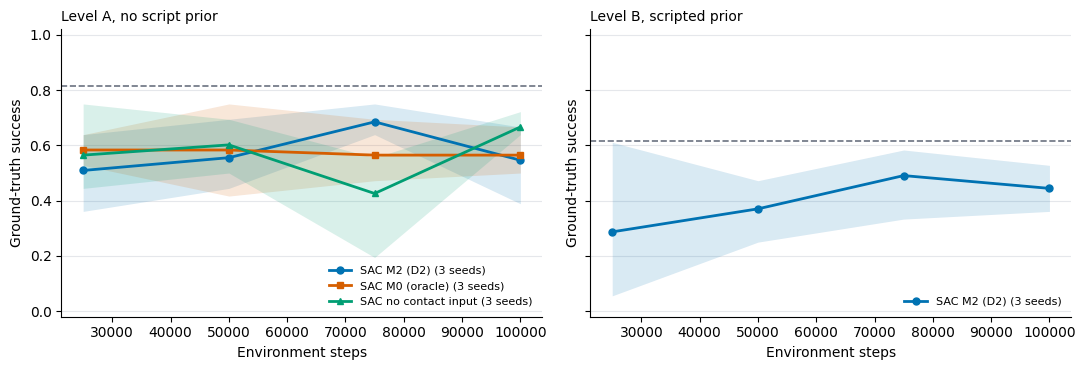

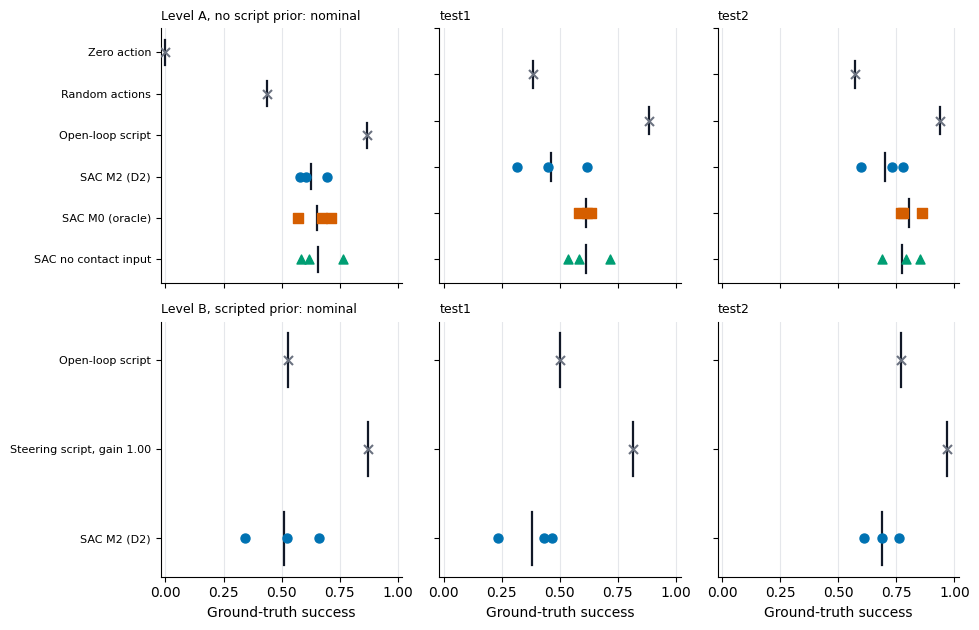

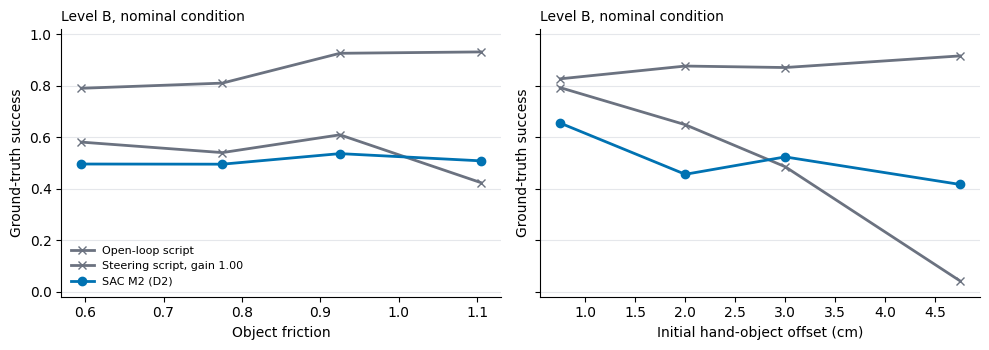

Tables and figures are in C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs\cv_v2\drl_runs_v3_final\results\v3_report


In [16]:
# V3.3 — Final Report
run_report()

In [17]:
# Cell 1 — Video setup
%run -i "VisuoGrasp_V33_Demo_Cell1.py"

Demo output: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs\cv_v2\drl_runs_v3_final\videos\v33_final_demos
Prepared cases: 8 | train/test1/test2 plus Level B


In [18]:
# Cell 2 — Record demonstrations
%run -i "VisuoGrasp_V33_Demo_Cell2.py"

[RECORD] A_train_success shape='box', train_seed=33, episode=10


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


[RECORD] A_train_failure shape='capsule', train_seed=22, episode=11


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


[RECORD] A_test1_success shape='box', train_seed=22, episode=0


c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


... (9 outputs left out)

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\stable_baselines3\common\off_policy_algorithm.py:182: UserWarning: `n_steps=10` is ignored because a custom `replay_buffer_class` (`NStepReplayBuffer`) was passed: n-step returns are only set up automatically when `replay_buffer_class` is `None`. To use n-step returns with a custom replay buffer, configure it explicitly, e.g. `replay_buffer_kwargs={"n_steps": 10, "gamma": 0.99}`.
  warnings.warn(


[WARNING] Replay GT differs from final_eval CSV: {'label': 'B_train_failure', 'policy': 'V3_B_SAC_M2', 'train_seed': 33, 'condition': 'nominal', 'shape': 'ring', 'episode': 18, 'episode_seed': 31050018, 'expected_gt': 0, 'actual_gt': 1, 'actual_cv': 0, 'frames_simulated': 200, 'file': 'B_train_failure.mp4'}


,label,shape,condition,train_seed,expected_gt,actual_gt,actual_cv,file
0,A_train_success,box,nominal,33,1,1,1,A_train_success.mp4
1,A_train_failure,capsule,nominal,22,0,0,0,A_train_failure.mp4
2,A_test1_success,box,test1,22,1,1,1,A_test1_success.mp4
3,A_test1_failure,ring,test1,33,0,0,0,A_test1_failure.mp4
4,A_test2_success,mug,test2,33,1,1,0,A_test2_success.mp4
5,A_test2_failure,bottle,test2,22,0,0,0,A_test2_failure.mp4
6,B_train_success,box,nominal,33,1,1,1,B_train_success.mp4
7,B_train_failure,ring,nominal,33,0,1,0,B_train_failure.mp4


Saved videos and GIFs in: C:\Users\user\Desktop\AMRL\Project_2_2\visuograsp_full_outputs\cv_v2\drl_runs_v3_final\videos\v33_final_demos
